In [1]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector
from qiskit import QuantumCircuit, QuantumRegister

from ApproximateEncoder import ApproximateEncoder
from GroverSearch import GroverSearch
from Visualization import state_analysis
from Loader import save_parameters, load_parameters

In [3]:
num_of_elements = 16
num_of_features = 4

hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features - 1, -1, -1)] for h in hex_images]

query_index = 7  
query = dataset[query_index]

In [4]:
dataset

[[0, 0, 0, 0],
 [0, 0, 0, 1],
 [0, 0, 1, 0],
 [0, 0, 1, 1],
 [0, 1, 0, 0],
 [0, 1, 0, 1],
 [0, 1, 1, 0],
 [0, 1, 1, 1],
 [1, 0, 0, 0],
 [1, 0, 0, 1],
 [1, 0, 1, 0],
 [1, 0, 1, 1],
 [1, 1, 0, 0],
 [1, 1, 0, 1],
 [1, 1, 1, 0],
 [1, 1, 1, 1]]

In [5]:
query_index

7

In [6]:
query

[0, 1, 1, 1]

# <u>**Part 1: Approximate Encoding Using PQC**</u>

Example for NEQR encoding scheme:

|dataset> = 1/root(N_I*N_D) summation |value> |feature no> |index>
            = |q6 q5 q4 q3 q2 q1 q0>
            = |v> |f1 f0> |i3 i2 i1 i0>

In [7]:
encoder = ApproximateEncoder()

In [8]:
pqc_depth_for_dataset_encoder = 9
pqc_depth_for_query_encoder = 3
epochs_dataset_encoder = 500
learning_rate_dataset_encoder = 0.1

## <u>**Encoding with NEQR scheme and MMD cost function**</u>


> Preparing dataset target state....

Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 64

> Starting training....

Number of parameters = 63


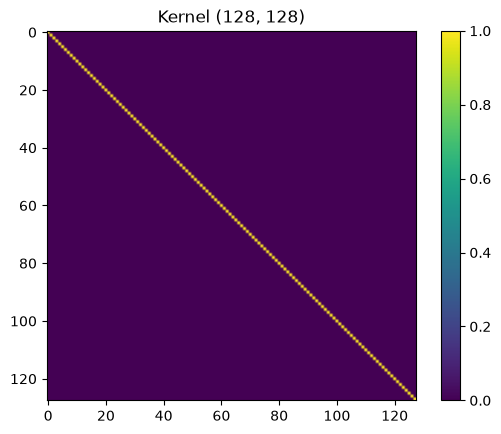


> Using adam optimization....
Epoch 1 - Loss 0.14374408255968438 - Fidelity 0.0015977970058641564
Epoch 2 - Loss 0.14260218595618201 - Fidelity 0.0013389856021577017
Epoch 3 - Loss 0.13655096774432585 - Fidelity 0.015975172044101232
Epoch 4 - Loss 0.11337634323096489 - Fidelity 0.05546660616198286
Epoch 5 - Loss 0.08296685082648499 - Fidelity 0.10193742262992282
Epoch 6 - Loss 0.0638195042098301 - Fidelity 0.13558807019025712
Epoch 7 - Loss 0.052736928802924715 - Fidelity 0.1659613164310075
Epoch 8 - Loss 0.046886573172211246 - Fidelity 0.19688561271098287
Epoch 9 - Loss 0.042010747189620626 - Fidelity 0.22543019861355934
Epoch 10 - Loss 0.0355856053812417 - Fidelity 0.25402411909061223
Epoch 11 - Loss 0.029679333110883534 - Fidelity 0.2805466959592069
Epoch 12 - Loss 0.026011688418033647 - Fidelity 0.29596844494163865
Epoch 13 - Loss 0.02371289213436761 - Fidelity 0.3013565272101039
Epoch 14 - Loss 0.021591958447400448 - Fidelity 0.30786910205933965
Epoch 15 - Loss 0.0198885113481257

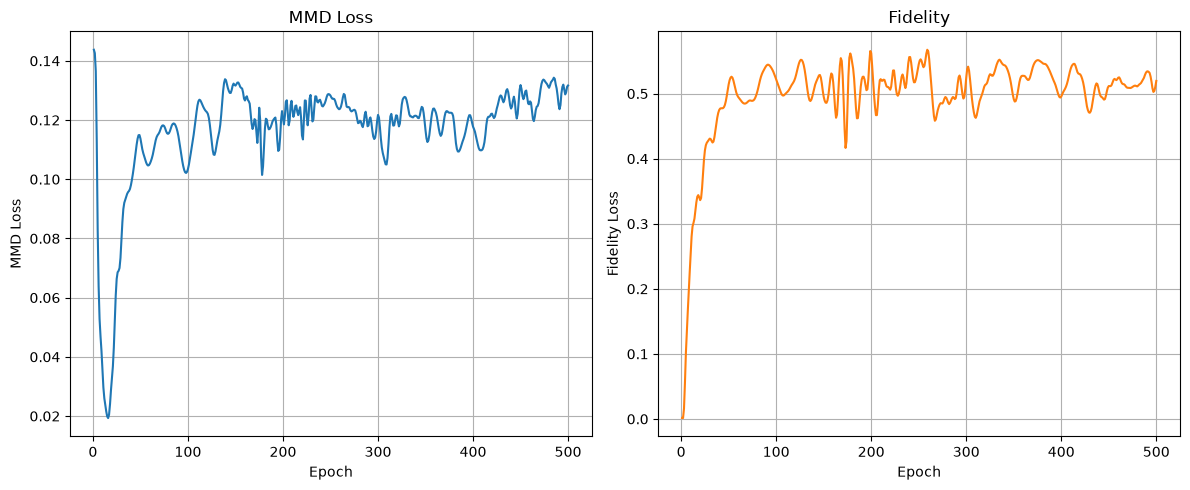


> Training finished.
Number of qubits: 7
Circuit depth (layers): 9
Number of parameters: 63
Best fidelity achieved: 0.56745525


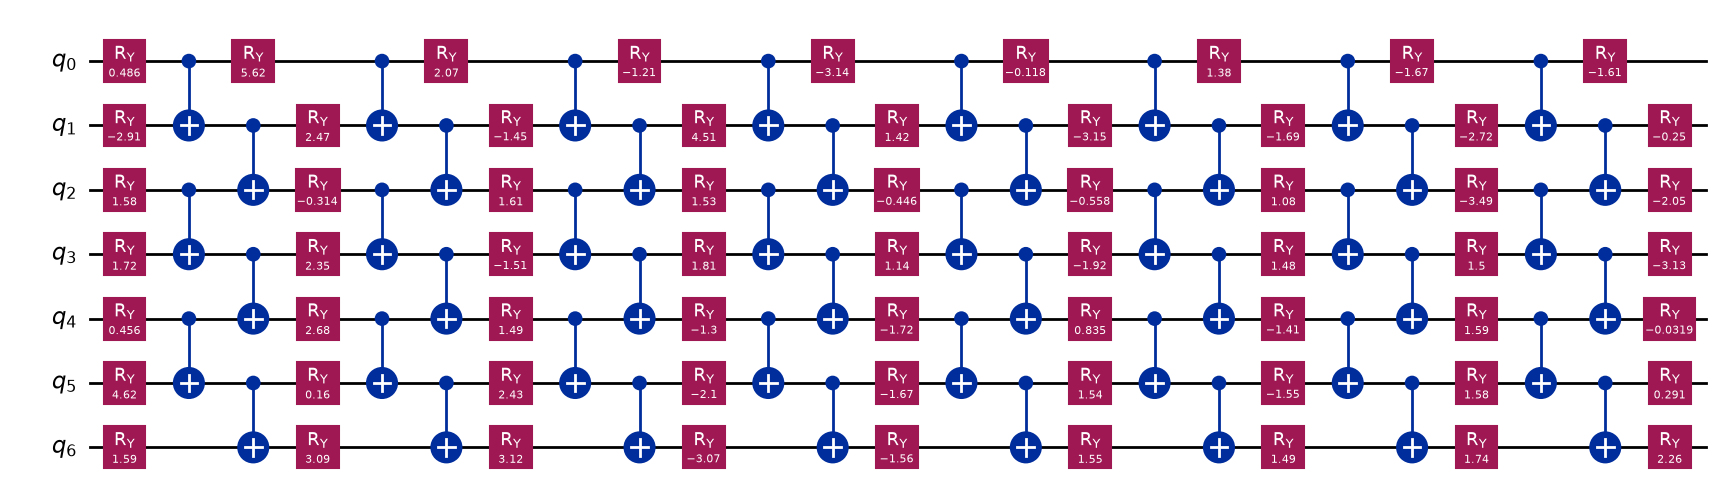


Data =  [[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.56745525


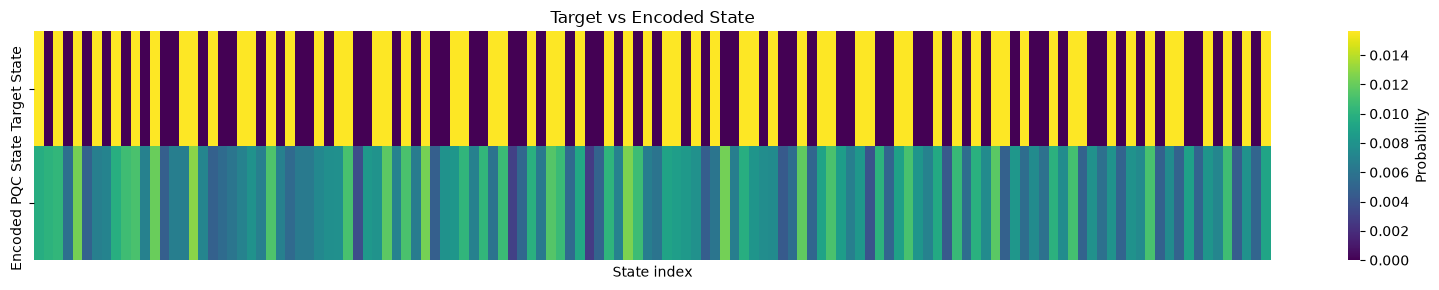

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

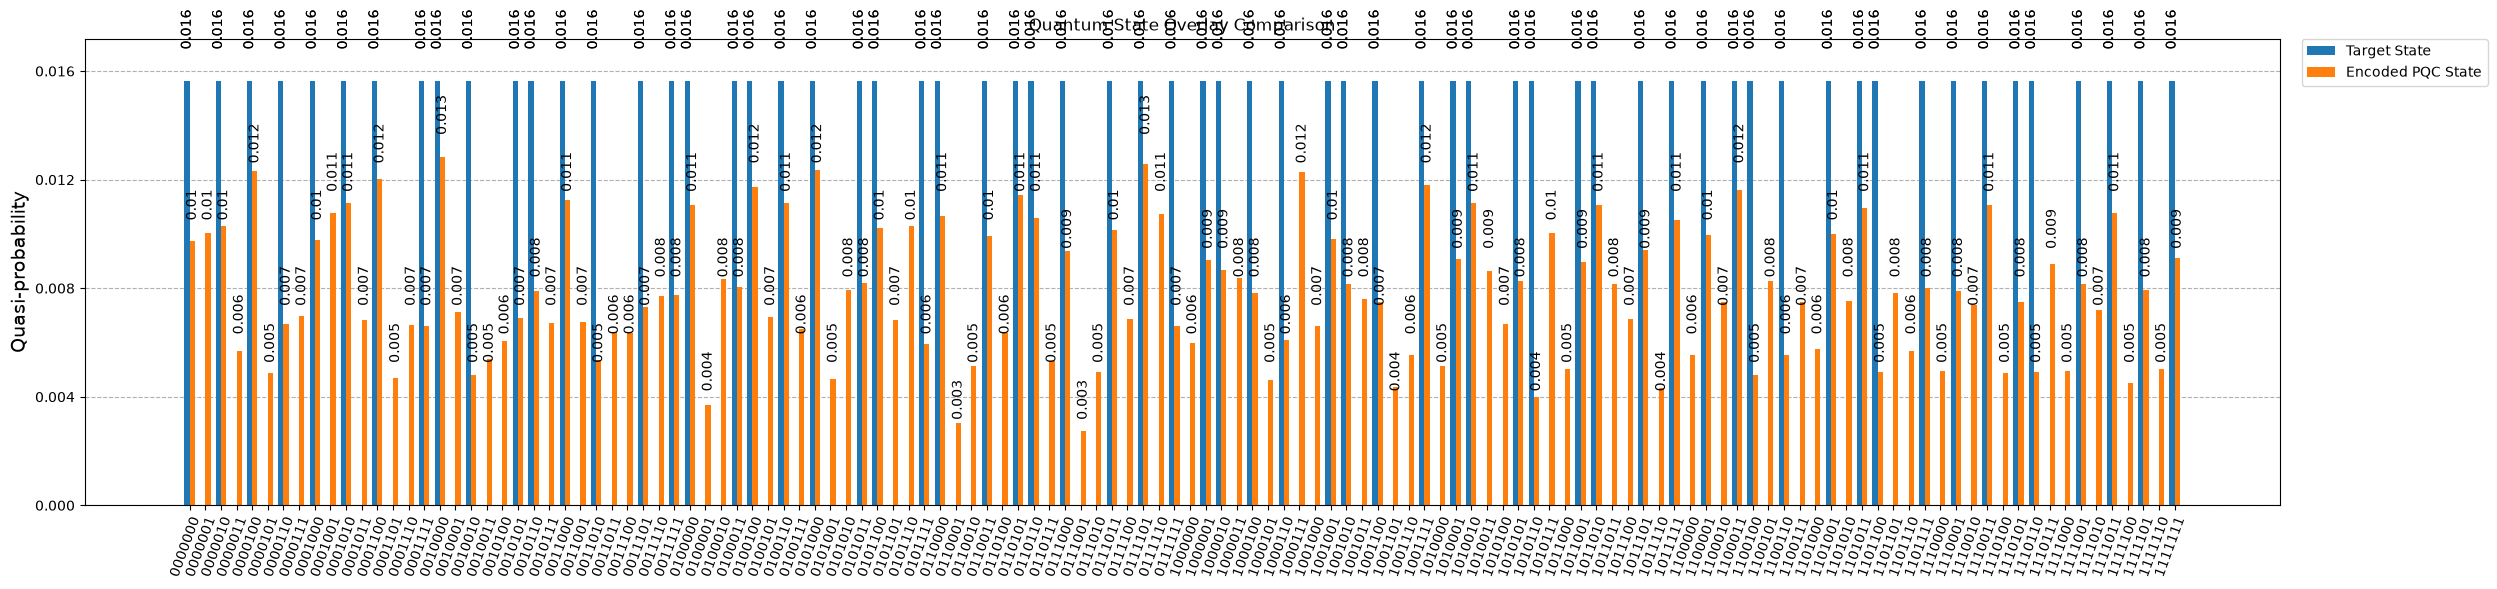


TARGET STATE
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.000                   
0                        1                        +0.125                   +0.000                   
0                        2                        +0.125                   +0.000                   
0                        3                        +0.125                   +0.000                   
1                        0                        +0.125                   +0.000                   
1                        1                        +0.125                   +0.000                   
1                        2                        +0.125                   +0.000                   
1                        3                        +0.000                   +0

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.09871515144626311+0j)
|0000001> : (-0.1002391461023619+0j)
|0000010> : (-0.10150956755218908+0j)
|0000011> : (-0.07546902157689257+0j)
|0000100> : (-0.1110609808770491+0j)
|0000101> : (-0.06981811693402694+0j)
|0000110> : (-0.08163567088811609+0j)
|0000111> : (-0.08347089586171079+0j)
|0001000> : (-0.09882895516063583+0j)
|0001001> : (-0.10372583128226265+0j)
|0001010> : (-0.10557426292309649+0j)
|0001011> : (-0.08253500284481569+0j)
|0001100> : (-0.1096930321594108+0j)
|0001101> : (-0.06845565107887698+0j)
|0001110> : (-0.08148160550526425+0j)
|0001111> : (-0.08129933477503079+0j)
|0010000> : (-0.11322710346201224+0j)
|0010001> : (-0.08438563963674692+0j)
|0010010> : (-0.0693457934019777+0j)
|0010011> : (-0.073345782985122+0j)
|0010100> : (-0.07791839341106412+0j)
|0010101> : (-0.08301930649397894+0j)
|0010110> : (-0.08890192924833186+0j)
|0010111> : (-0.08206445462676716+0j)
|0011000> : (-0.10613098482170963+0j)
|0011001> : (-0.0821009563

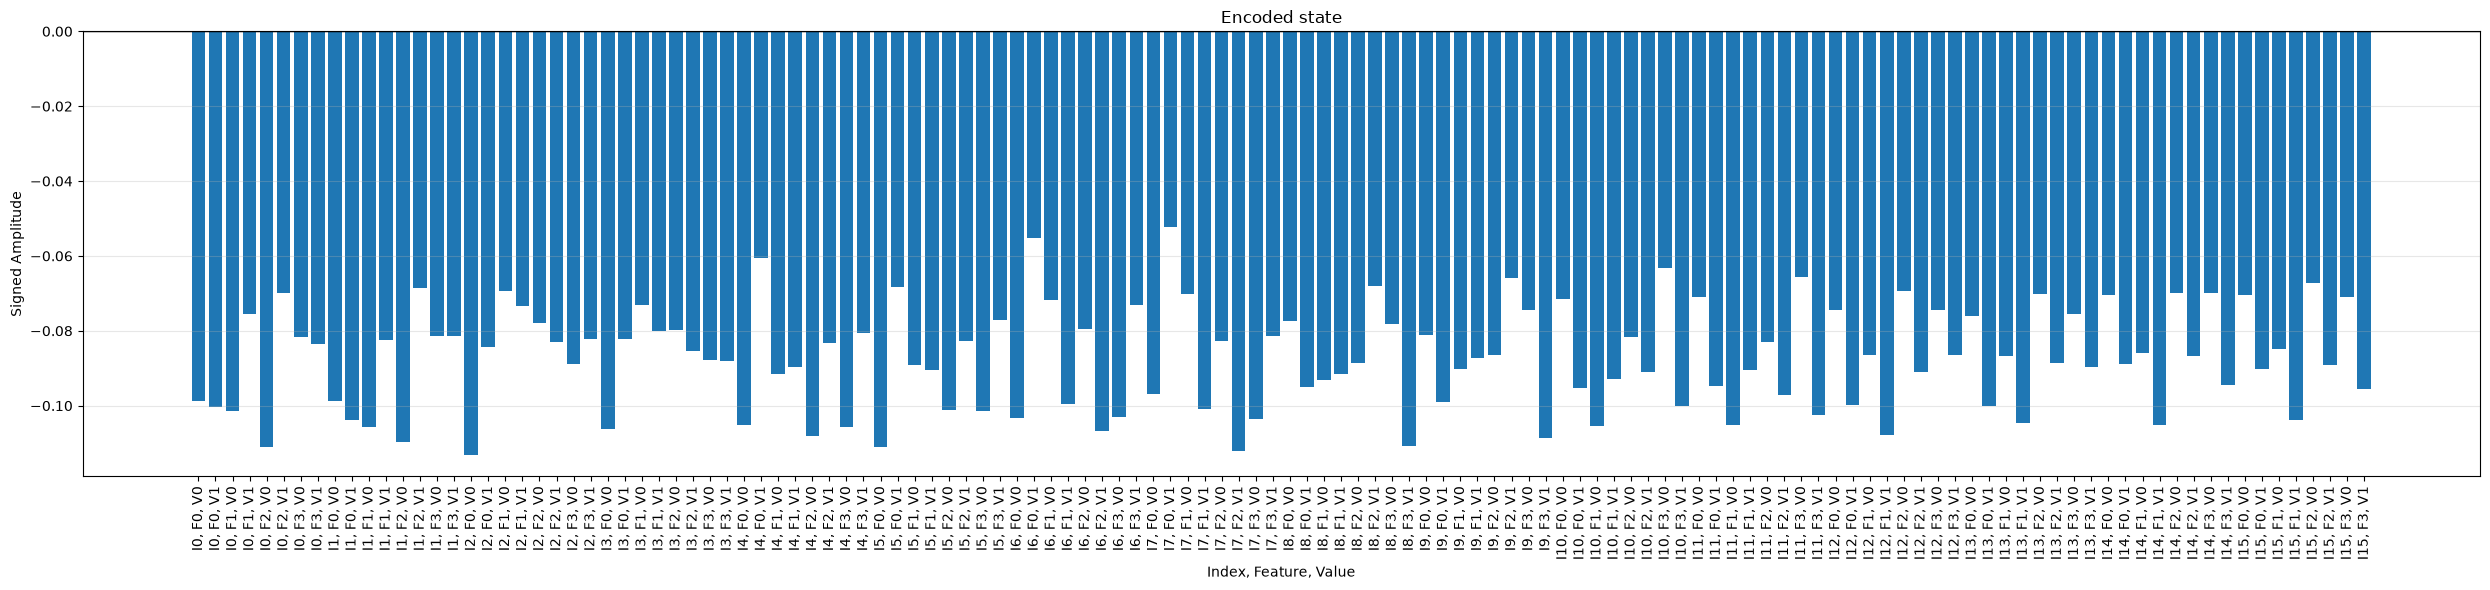


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


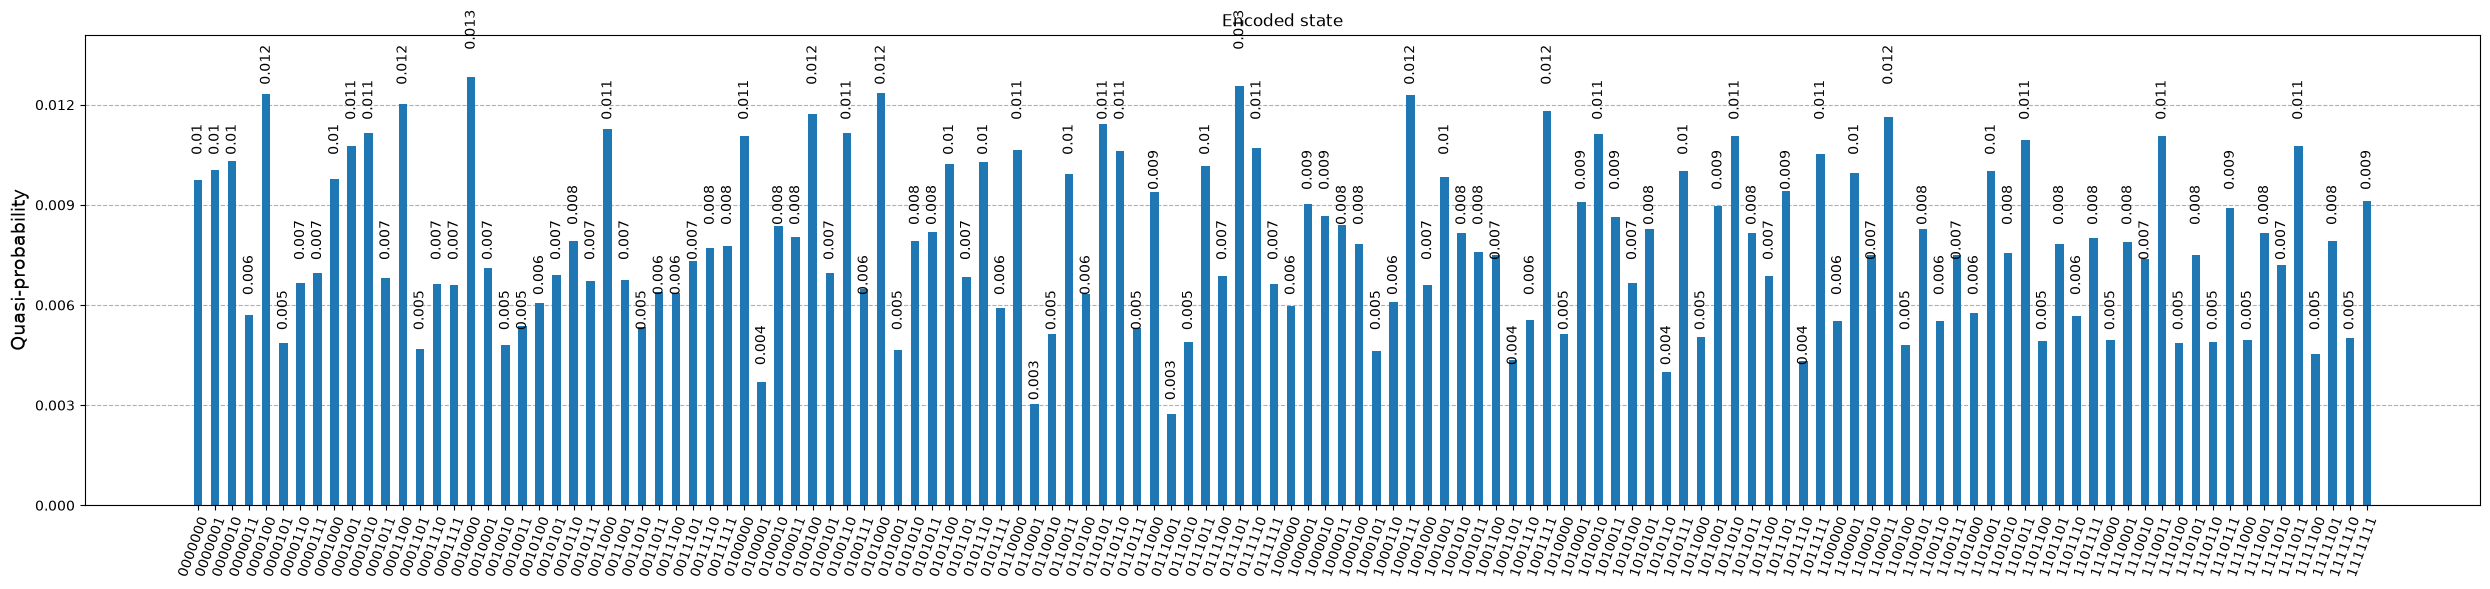

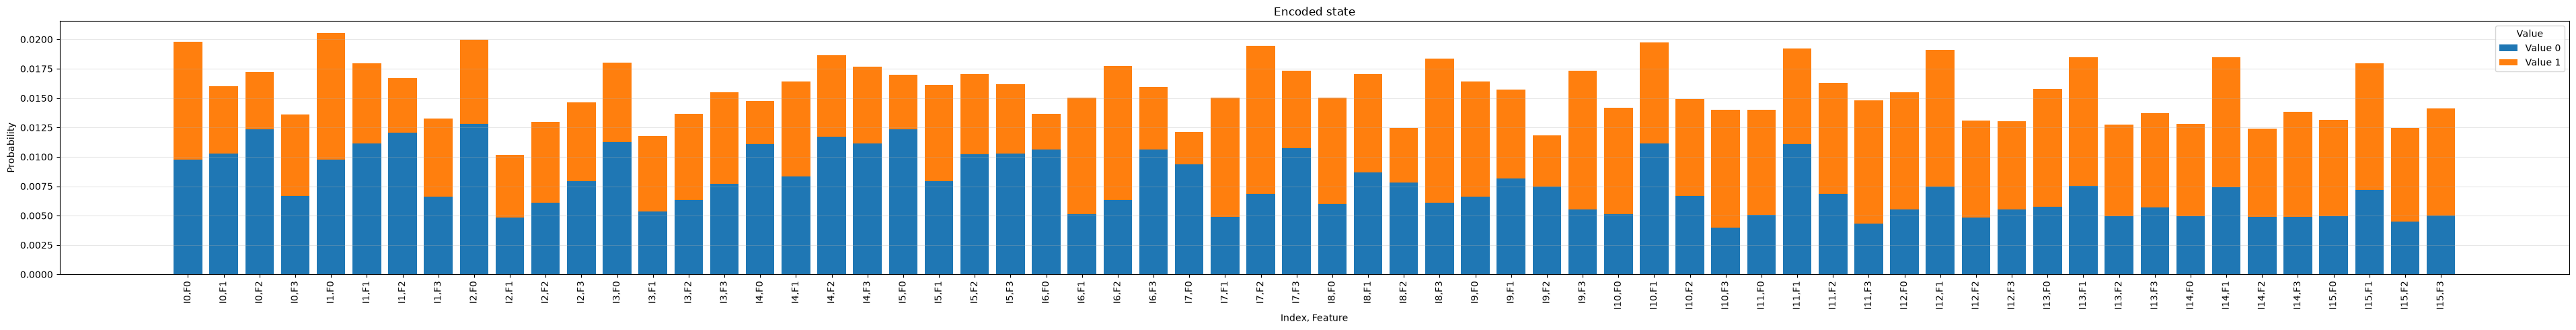


Encoded state
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.099                   -0.100                   
0                        1                        -0.102                   -0.075                   
0                        2                        -0.111                   -0.070                   
0                        3                        -0.082                   -0.083                   
1                        0                        -0.099                   -0.104                   
1                        1                        -0.106                   -0.083                   
1                        2                        -0.110                   -0.068                   
1                        3                        -0.081                   -

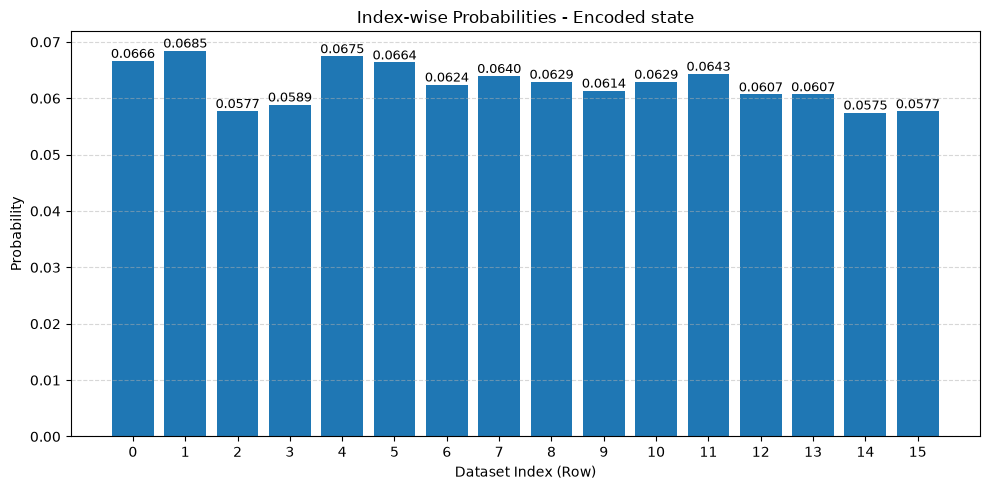

In [9]:
A_parameters_neqr_mmd, _ = encoder.generate_encoding(dataset, scheme="NEQR", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, learning_rate=learning_rate_dataset_encoder, loss_function_type="MMD")


> Preparing query target state....

Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8

Amplitude =  0.5

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 4

> Starting training....

Number of parameters = 9


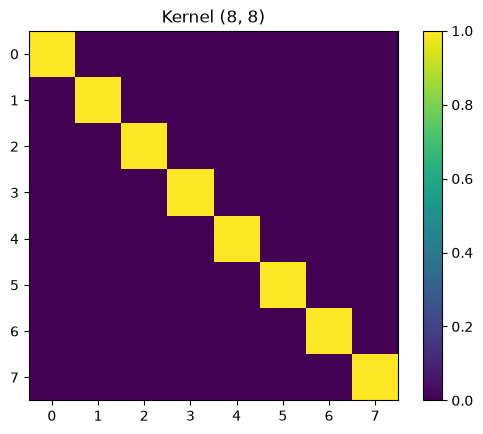


> Using adam optimization....
Epoch 1 - Loss 0.16938011020439608 - Fidelity 0.0956929274493287
Epoch 2 - Loss 0.1529397131034705 - Fidelity 0.14728242917958806
Epoch 3 - Loss 0.14430849693117462 - Fidelity 0.21801285327425587
Epoch 4 - Loss 0.141199670618158 - Fidelity 0.30255482828511093
Epoch 5 - Loss 0.1378401515878041 - Fidelity 0.3945851915310629
Epoch 6 - Loss 0.132110786903119 - Fidelity 0.48714094183439116
Epoch 7 - Loss 0.12493029934613414 - Fidelity 0.572244971717477
Epoch 8 - Loss 0.119241268840972 - Fidelity 0.6426290432775041
Epoch 9 - Loss 0.11620047474243597 - Fidelity 0.6933339671902448
Epoch 10 - Loss 0.11315470033026881 - Fidelity 0.7205695632026177
Epoch 11 - Loss 0.10778599651134399 - Fidelity 0.725419081753289
Epoch 12 - Loss 0.10151228663988693 - Fidelity 0.7177471428679194
Epoch 13 - Loss 0.09676697869338993 - Fidelity 0.7093507505040242
Epoch 14 - Loss 0.0941729115368013 - Fidelity 0.7042044974471823
Epoch 15 - Loss 0.09317925732390997 - Fidelity 0.699573001591

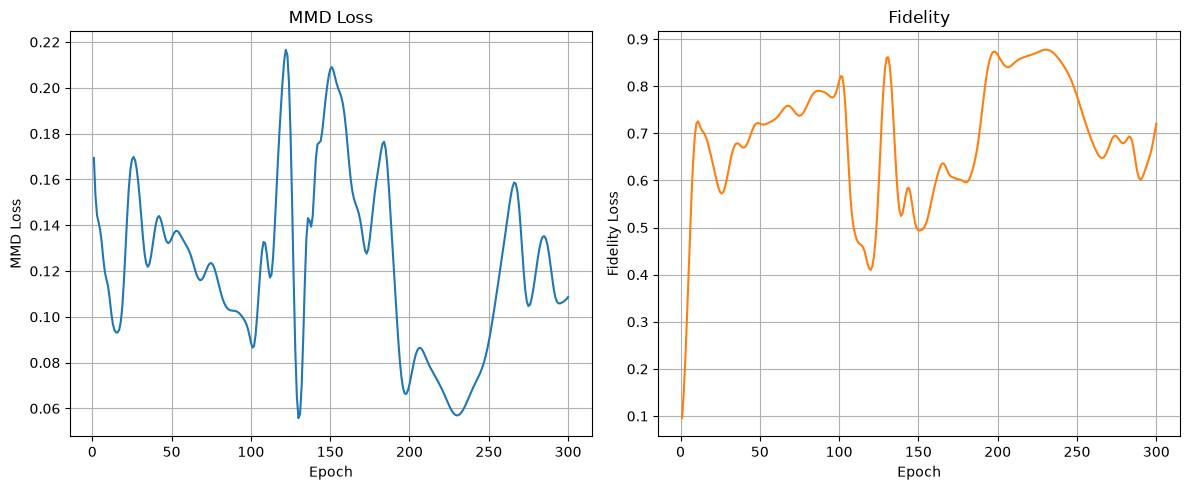


> Training finished.
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Best fidelity achieved: 0.87736560


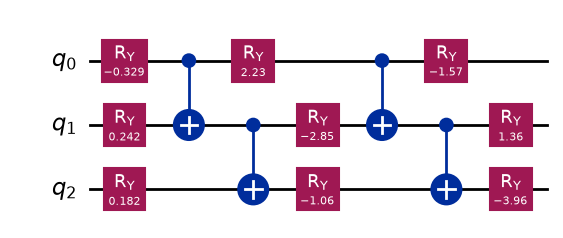


Data =  [0 1 1 1]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.87736560


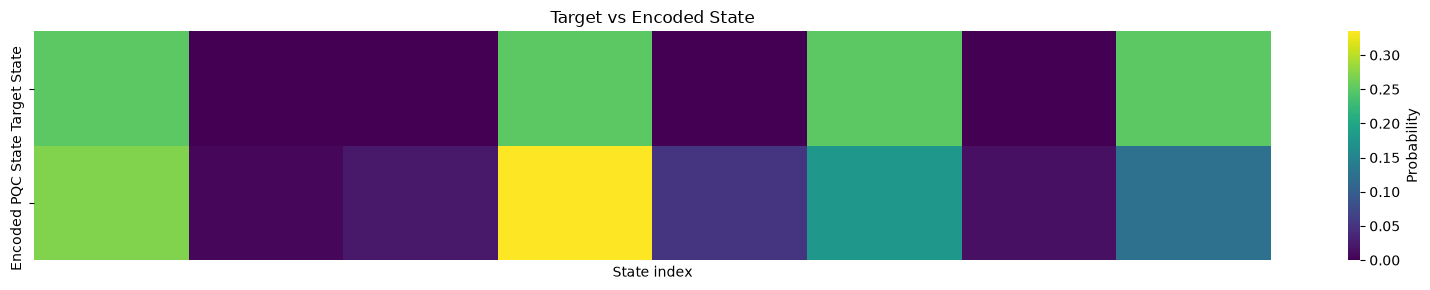

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

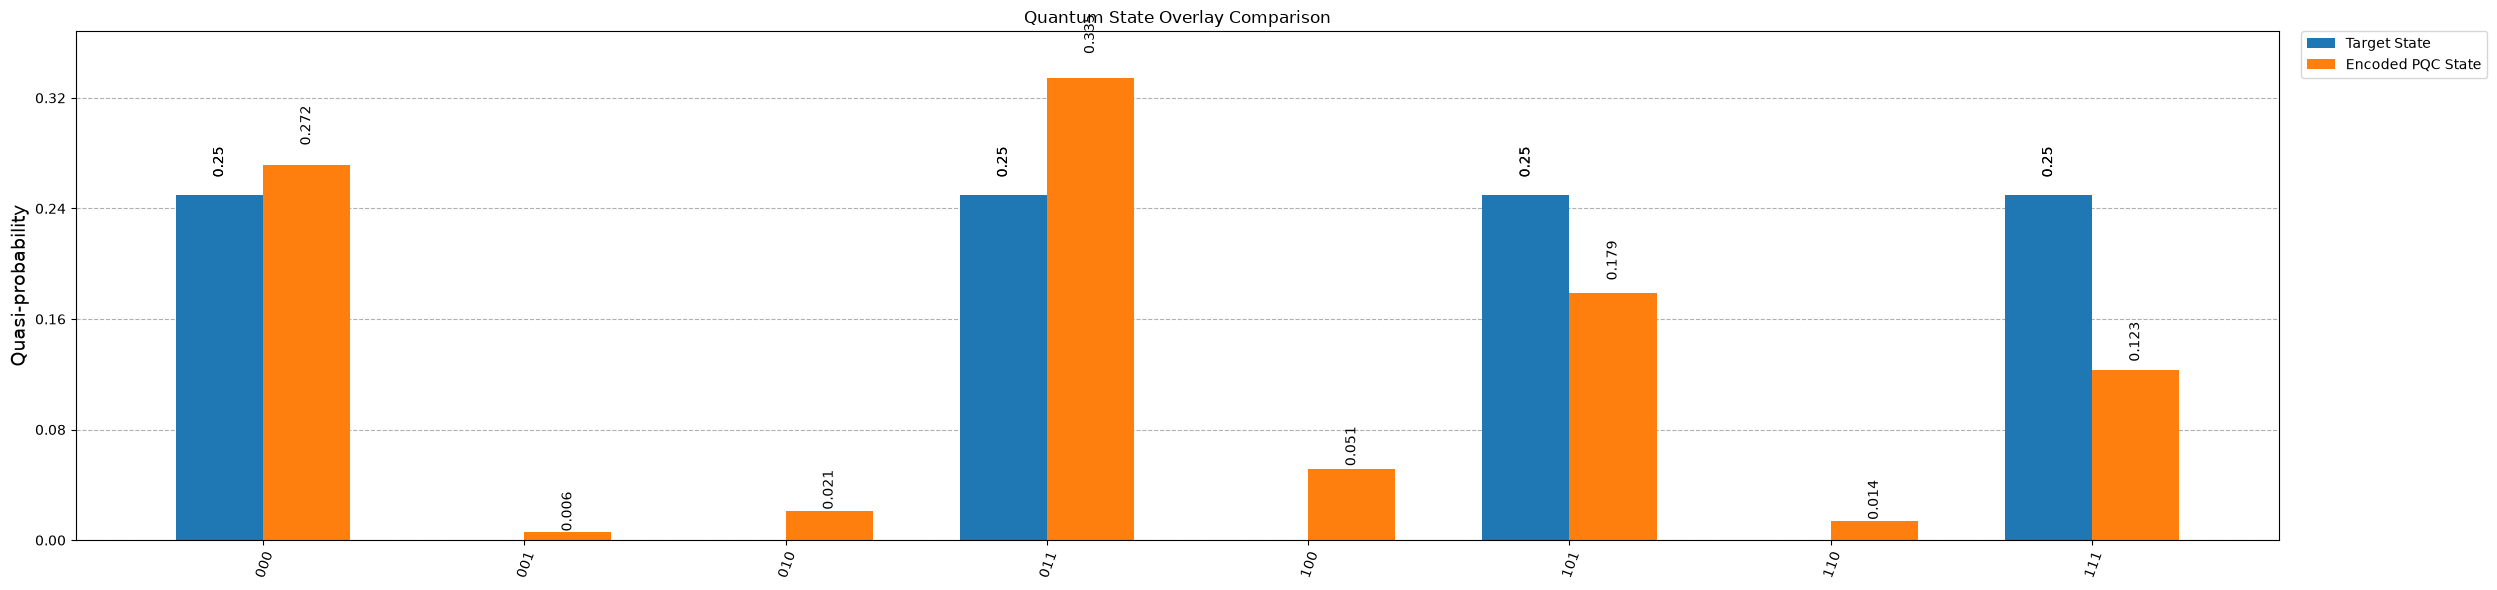


TARGET STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.500                   +0.000                   
1                        +0.000                   +0.500                   
2                        +0.000                   +0.500                   
3                        +0.000                   +0.500                   

ENCODED STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.521                   +0.076                   
1                        +0.145                   +0.579                   
2                        +0.226                   +0.423                   
3                        +0.118                   +0.351                   

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000> : (0.5211548623347703+0j)
|001> : (0.07578538545389178+0j)
|010> : (0.14478388892887795+0j)
|011> : (0.5785266290943961+0j)
|100> : (0.2261755710789597+0j)
|101> : (0.42284588592537925+0j)
|110> : (0.11816958392975105+0j)
|111> : (0.35082854357747745+0j)


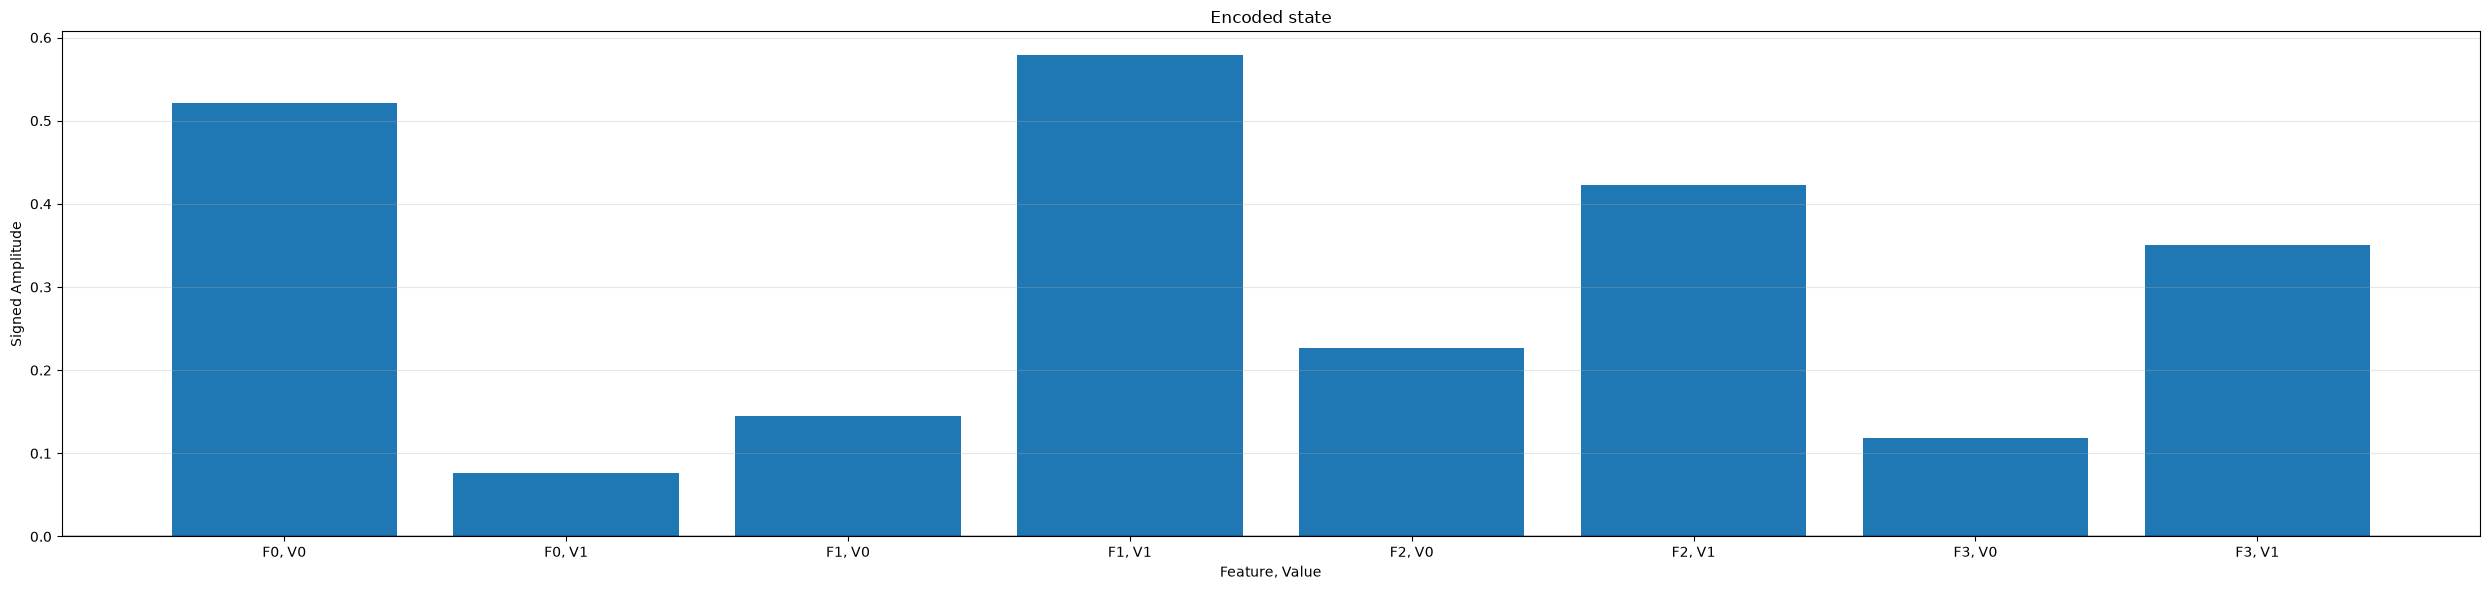


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


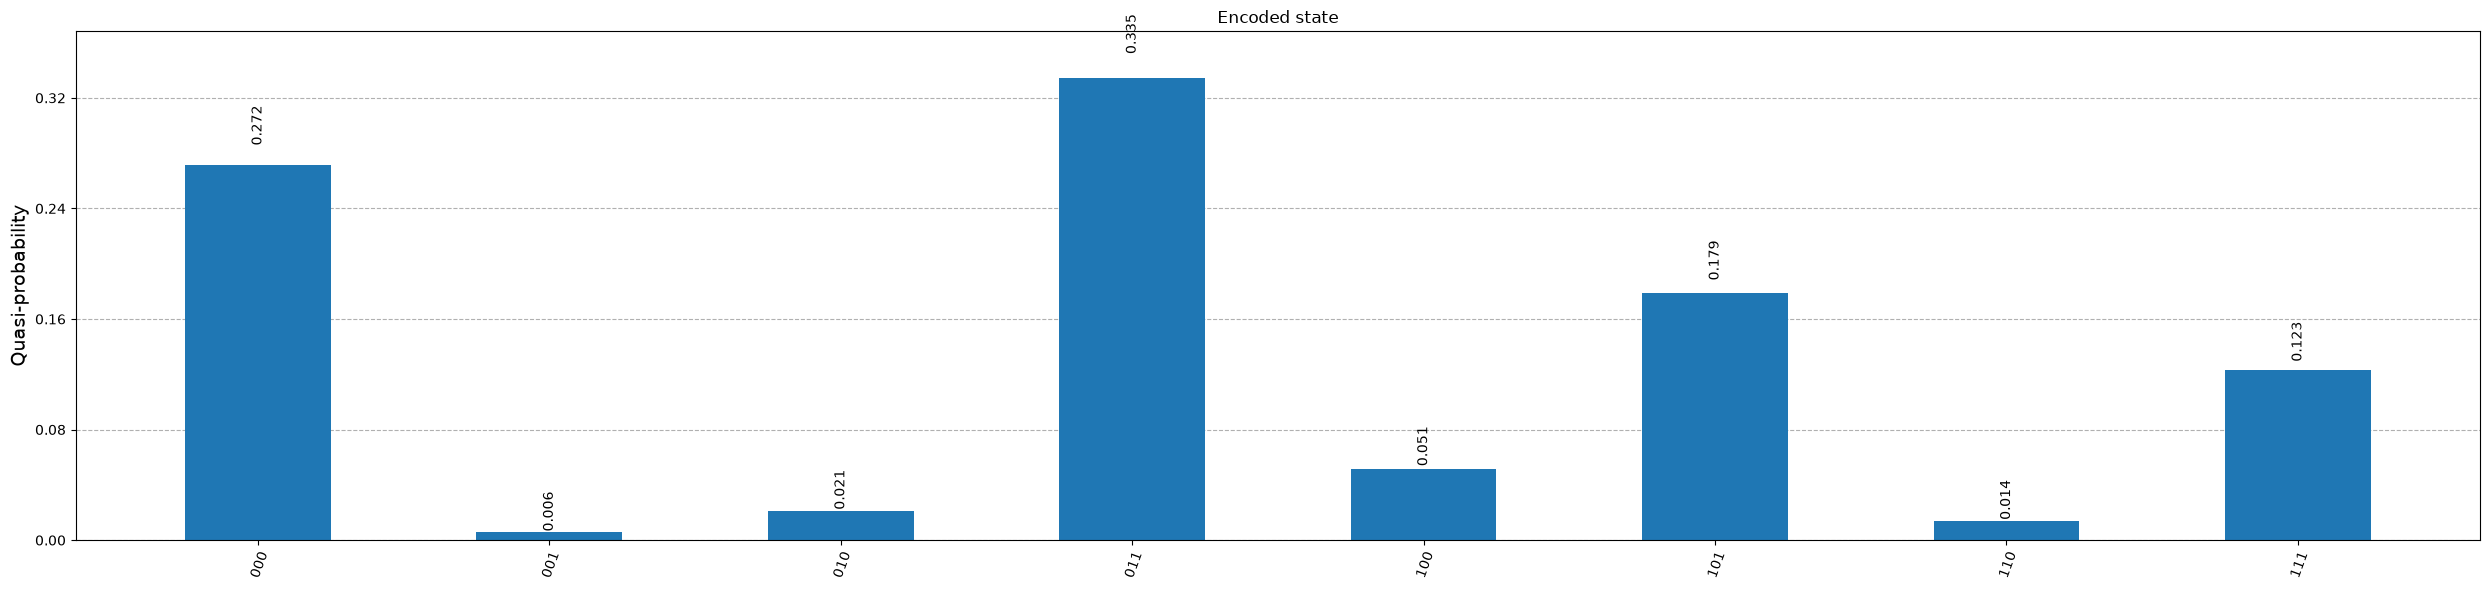

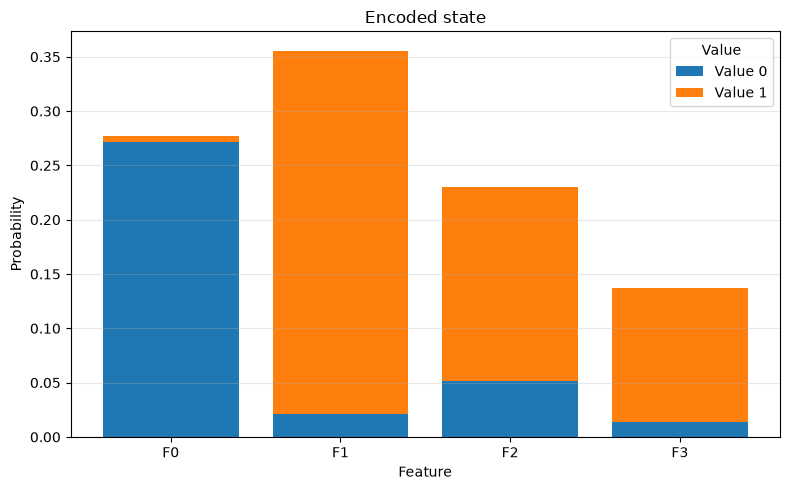


Encoded state
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.521                   +0.076                   
1                        +0.145                   +0.579                   
2                        +0.226                   +0.423                   
3                        +0.118                   +0.351                   


In [10]:
B_parameters_neqr_mmd, _ = encoder.generate_encoding(query, scheme="NEQR", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.1, loss_function_type="MMD")

## <u>**Encoding with NEQR scheme and FIDELITY cost function**</u>

Fidelity ignore global phase but captures relative phase.

Example, 

{a|0> + b|1>} and {-a|0>-b|1>} are physically identical

But for (|0>+|1>)/root(2) and (|0>-|1>)/root(2), fidelity is zero (different states)

In [11]:
# Load previously saved A, if available
A_saved_best_fidelity = 0

try:
    A_saved = load_parameters(scheme="NEQR", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.3f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset encoder. Train again.")

Loaded saved dataset encoder. Fidelity = 0.992



> Preparing dataset target state....

Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 64

> Starting training....

Number of parameters = 63

> Using adam optimization....
Epoch 1 - Loss 0.9483575097187129 - Fidelity 0.05164249028128708
Epoch 2 - Loss 0.8545876539897213 - Fidelity 0.1454123460102788
Epoch 3 - Loss 0.7575838289412781 - Fidelity 0.24241617105872196
Epoch 4 - Loss 0.7010676431187686 - Fidelity 0.29893235688123143
Epoch 5 - Loss 0.6518348346823295 - Fidelity 0.3481651653176705
Epoch 6 - Loss 0.5966294612588348 - Fidelity 0.4033705387411653
Epoch 7 - Loss 0.5432101716107722 - Fidelity 0.4567898283892277
Epoch 8 - Loss 0.49314415623964636 - Fidelity 0.5068558437603536
Epoch 9 - Loss 0.45122939396051576 - Fidelity 0.5487706060394842
Epoch 10 - Loss 0.42385673037172333 - Fidelity 0.5761432696282767
Epoch 11 - Loss 0.4120700193484298 - Fidelity 0.5879299806515702
Epoch 12 - Loss 0.40433247947214535 - Fidelity 0.5956675205278547
Epoch 13 - Loss 0.3906756947168383 - Fidelity 0.6093243052831617
Epoch 14 - Loss 0.373001602720513

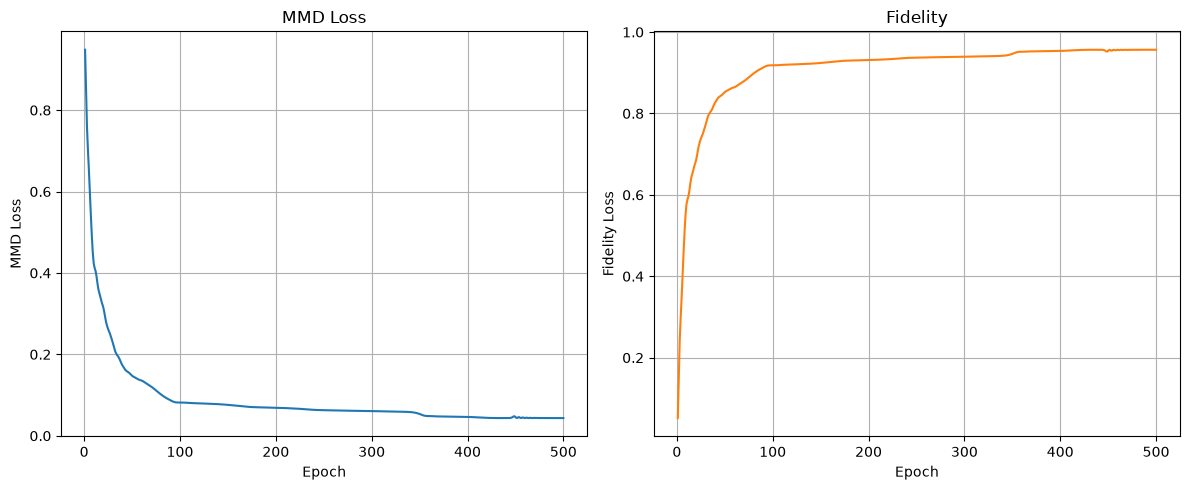


> Training finished.
Number of qubits: 7
Circuit depth (layers): 9
Number of parameters: 63
Best fidelity achieved: 0.95653215


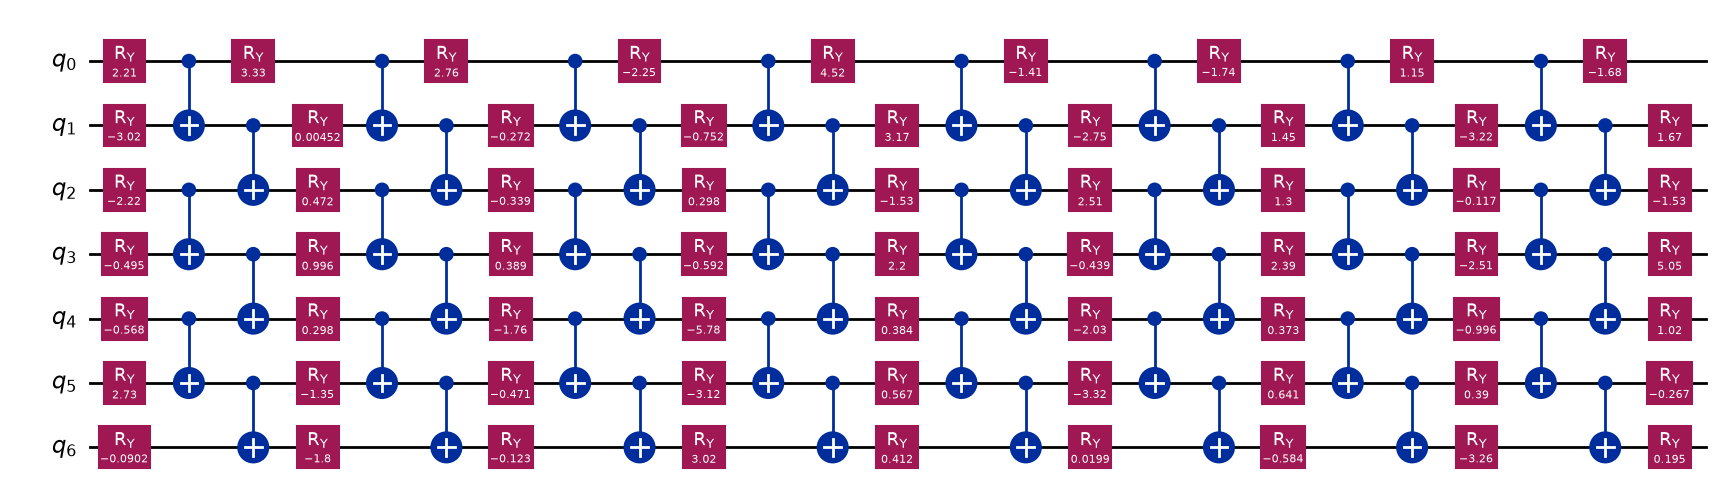


Data =  [[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.95653215


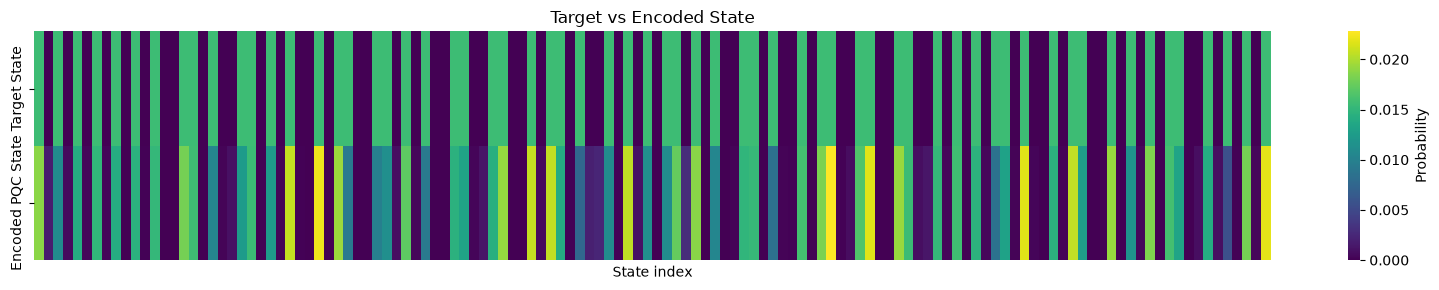

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

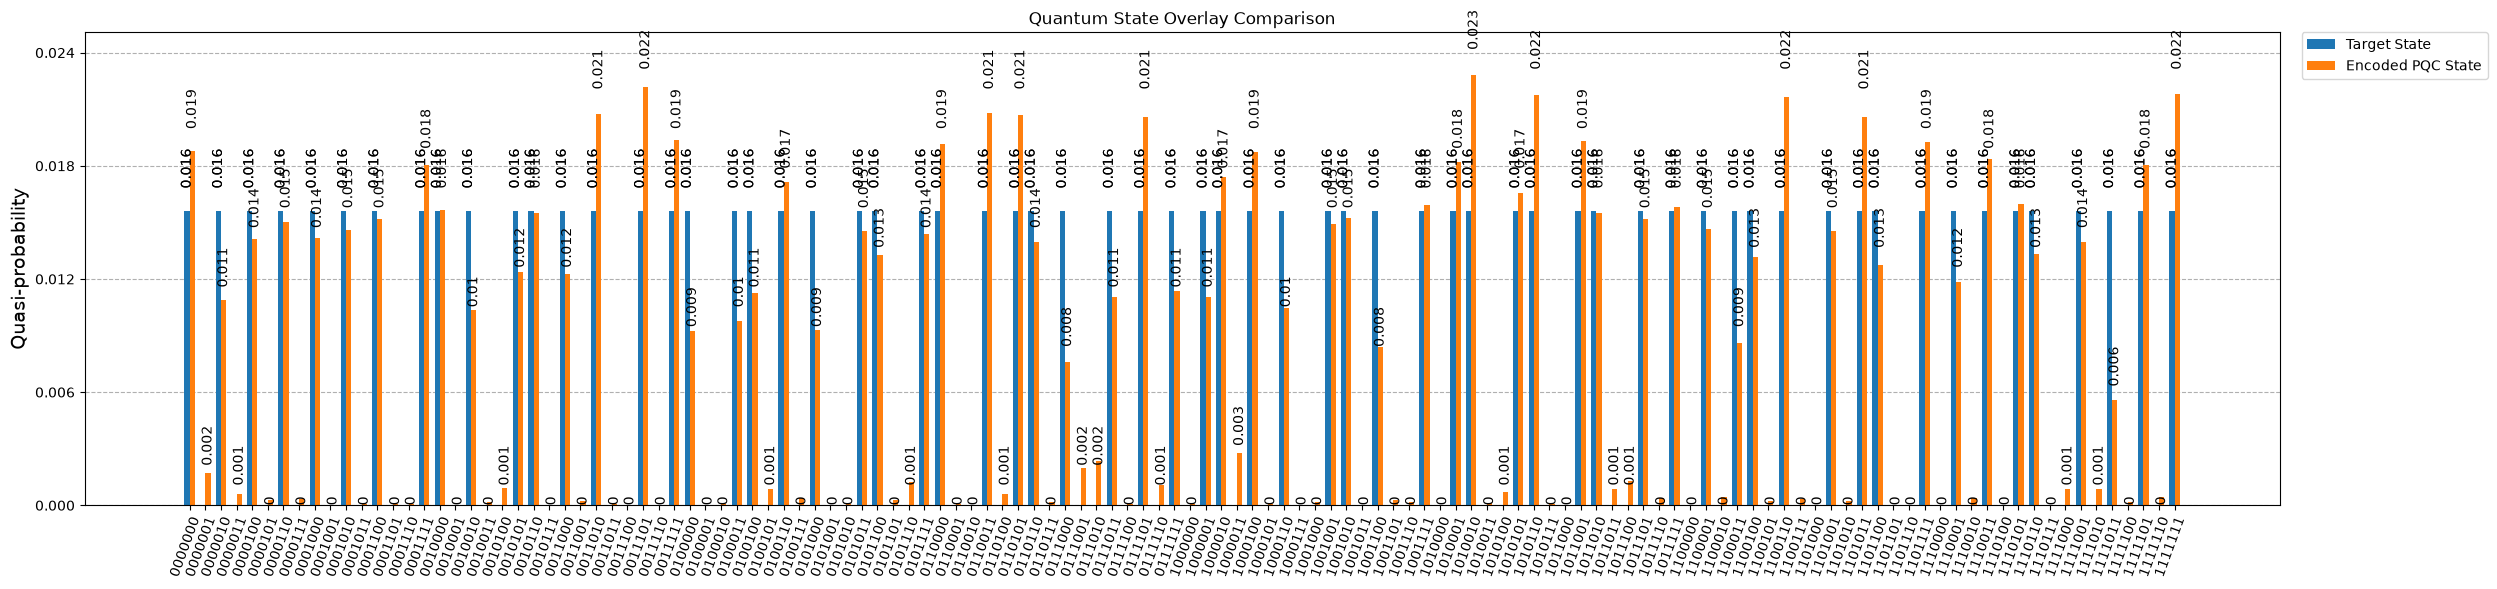


TARGET STATE
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.000                   
0                        1                        +0.125                   +0.000                   
0                        2                        +0.125                   +0.000                   
0                        3                        +0.125                   +0.000                   
1                        0                        +0.125                   +0.000                   
1                        1                        +0.125                   +0.000                   
1                        2                        +0.125                   +0.000                   
1                        3                        +0.000                   +0

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.13710964843751183+0j)
|0000001> : (-0.04130529853231385+0j)
|0000010> : (-0.1043193035401722+0j)
|0000011> : (-0.02408599472166419+0j)
|0000100> : (-0.11886429740260997+0j)
|0000101> : (-0.016493909705884786+0j)
|0000110> : (-0.12258368815851908+0j)
|0000111> : (-0.01795577264808744+0j)
|0001000> : (-0.11897286764918447+0j)
|0001001> : (0.0028026045344682502+0j)
|0001010> : (-0.12081004170079568+0j)
|0001011> : (0.009717373381552373+0j)
|0001100> : (-0.12327594590893874+0j)
|0001101> : (0.008011166567495996+0j)
|0001110> : (-0.006977817917048014+0j)
|0001111> : (-0.13423416608172115+0j)
|0010000> : (-0.1252268137509432+0j)
|0010001> : (-0.006268710699631183+0j)
|0010010> : (-0.1016921442410497+0j)
|0010011> : (0.013749951721016673+0j)
|0010100> : (0.030717326688671664+0j)
|0010101> : (-0.1113074677392076+0j)
|0010110> : (-0.12458790002058719+0j)
|0010111> : (0.005296149480597135+0j)
|0011000> : (-0.11072635089463213+0j)
|0011001> : (0.01554

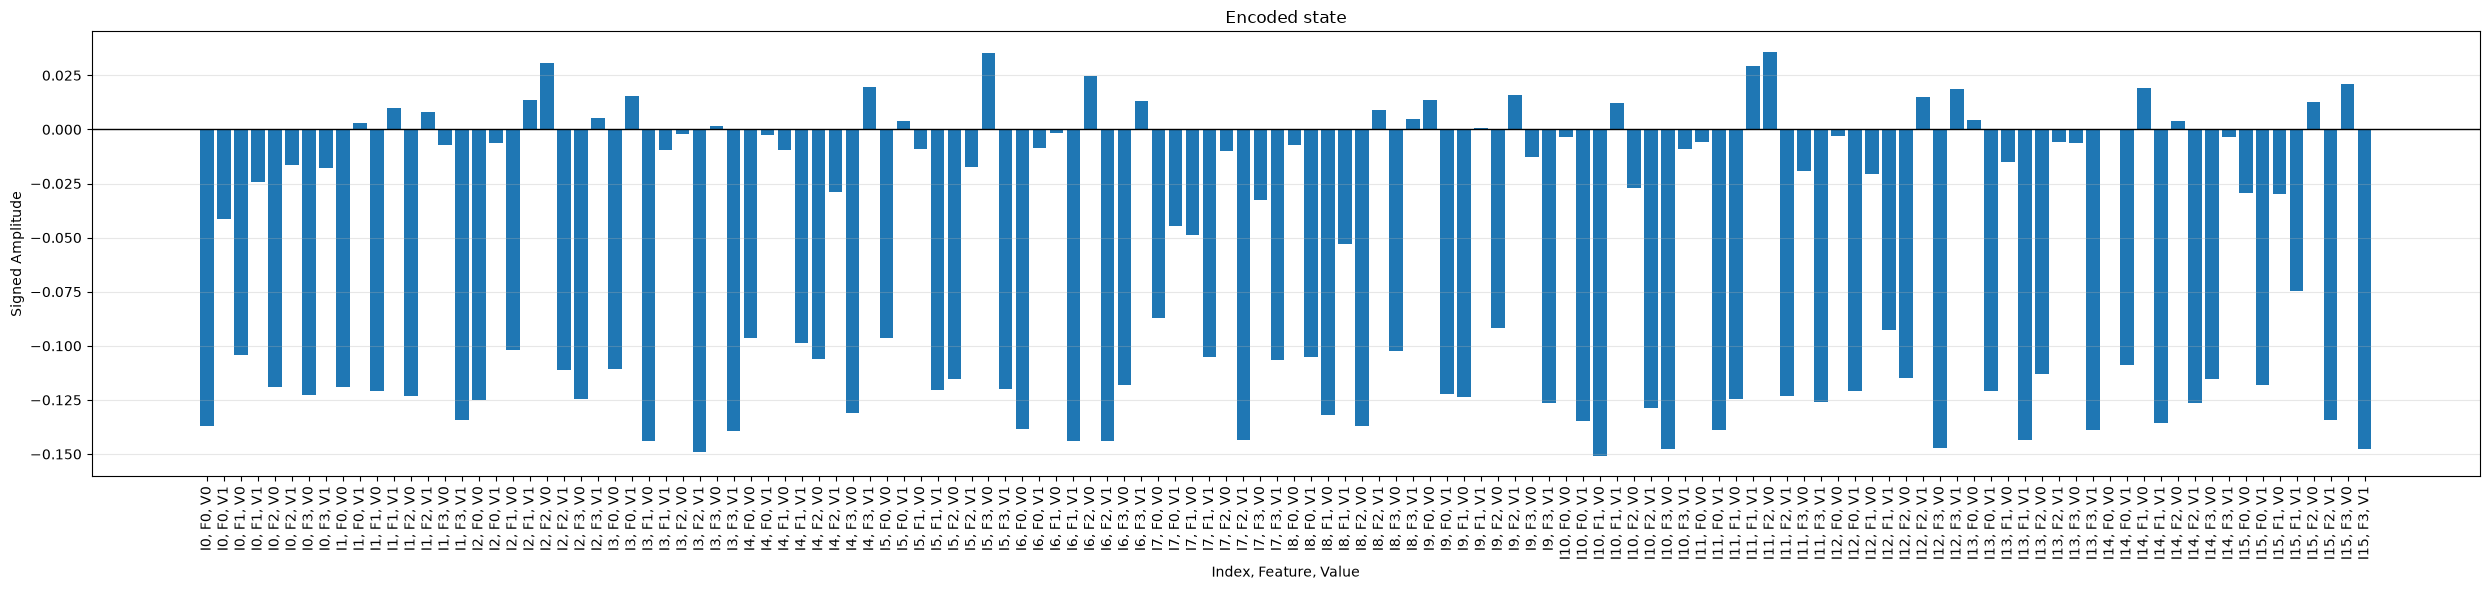


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


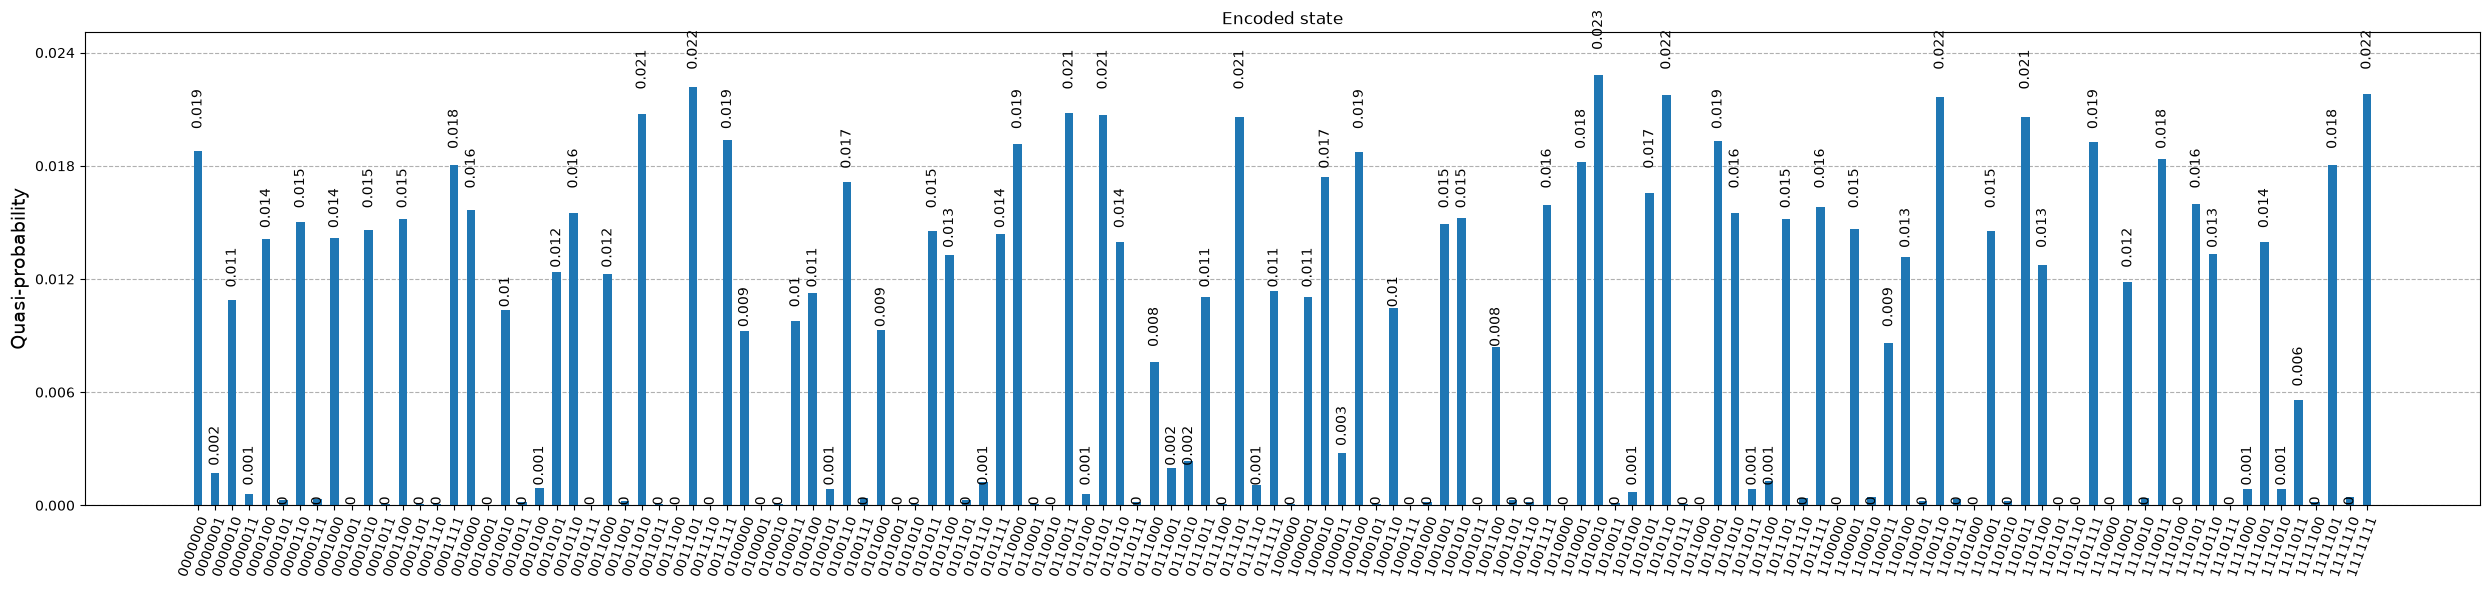

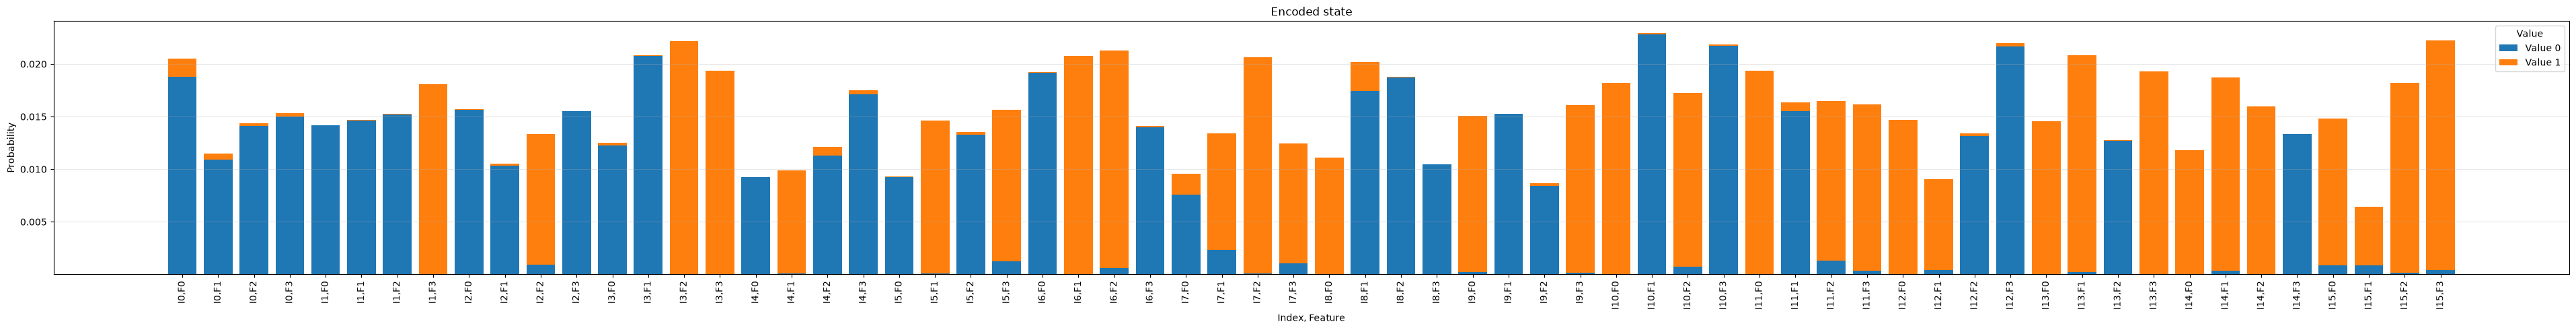


Encoded state
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.137                   -0.041                   
0                        1                        -0.104                   -0.024                   
0                        2                        -0.119                   -0.016                   
0                        3                        -0.123                   -0.018                   
1                        0                        -0.119                   +0.003                   
1                        1                        -0.121                   +0.010                   
1                        2                        -0.123                   +0.008                   
1                        3                        -0.007                   -

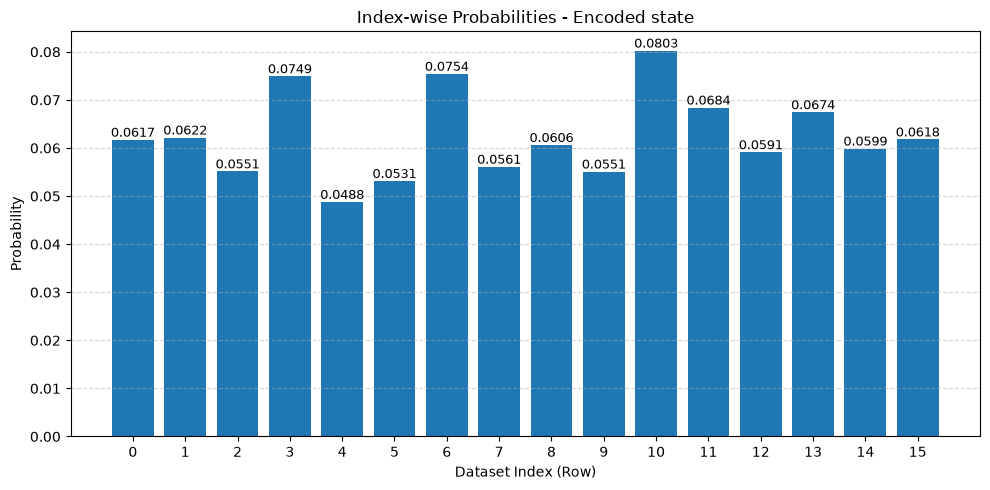

In [12]:
A_parameters, A_best_fidelity = encoder.generate_encoding(dataset, scheme="NEQR", depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, learning_rate=learning_rate_dataset_encoder, loss_function_type="FIDELITY")

In [13]:
# SAVE THE BEST PERFORMING DATASET ENCODER

if A_best_fidelity > A_saved_best_fidelity:
    save_parameters(
        A_parameters,
        depth=pqc_depth_for_dataset_encoder, epochs=epochs_dataset_encoder, 
        learning_rate=learning_rate_dataset_encoder, fidelity=A_best_fidelity,
        scheme="NEQR", loss_function_type="FIDELITY"
    )

    print("New dataset encoder has better fidelity. Saved the new parameters.")

else:
    print(f"New dataset encoder did not improve fidelity {A_saved_best_fidelity}. Keeping the previous best parameters.")
    A_parameters = A_saved_parameters
    A_best_fidelity = A_saved_best_fidelity

print(f"Final best dataset encoder fidelity = {A_best_fidelity:.3f}")

New dataset encoder did not improve fidelity 0.9921147297951308. Keeping the previous best parameters.
Final best dataset encoder fidelity = 0.992



> Preparing query target state....

Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8

Amplitude =  0.5

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 4

> Starting training....

Number of parameters = 9

> Using adam optimization....
Epoch 1 - Loss 0.8380576291441276 - Fidelity 0.16194237085587238
Epoch 2 - Loss 0.719267199709586 - Fidelity 0.28073280029041403
Epoch 3 - Loss 0.5791459575141622 - Fidelity 0.42085404248583774
Epoch 4 - Loss 0.43334561903867586 - Fidelity 0.5666543809613241
Epoch 5 - Loss 0.30099626270760116 - Fidelity 0.6990037372923988
Epoch 6 - Loss 0.20504822528417121 - Fidelity 0.7949517747158288
Epoch 7 - Loss 0.16038841431079098 - Fidelity 0.839611585689209
Epoch 8 - Loss 0.15944992246492184 - Fidelity 0.8405500775350782
Epoch 9 - Loss 0.17892449283755207 - Fidelity 0.8210755071624479
Epoch 10 - Loss 0.19687074496562962 - Fidelity 0.8031292550343704
Epoch 11 - Loss 0.20287913664515667 - Fidelity 0.7971208633548433
Epoch 12 - Loss 0.19673086399411588 - Fidelity 0.8032691360058841
Epoch 13 - Loss 0.18319096066267915 - Fidelity 0.8168090393373209
Epoch 14 - Loss 0.1678280109246

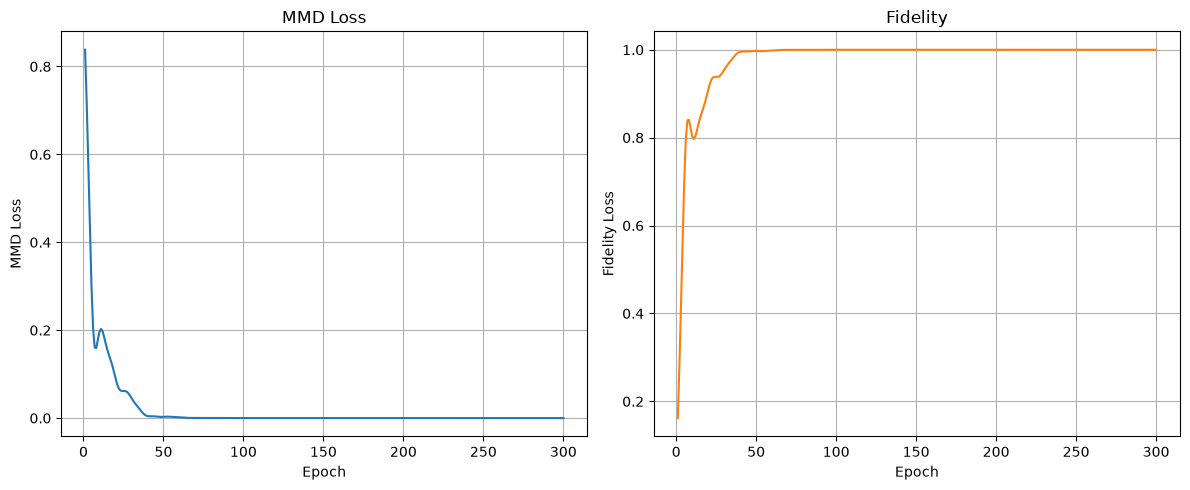


> Training finished.
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Best fidelity achieved: 0.99999944


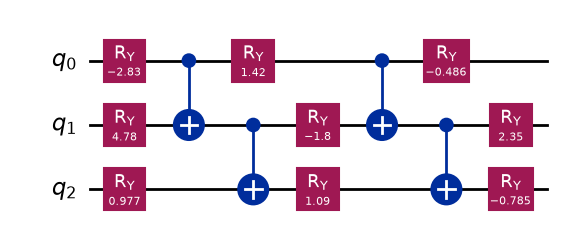


Data =  [0 1 1 1]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99999944


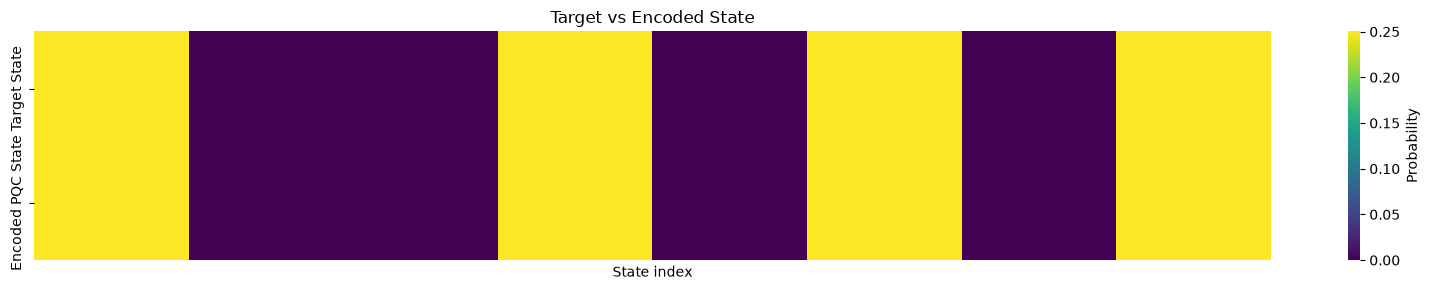

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

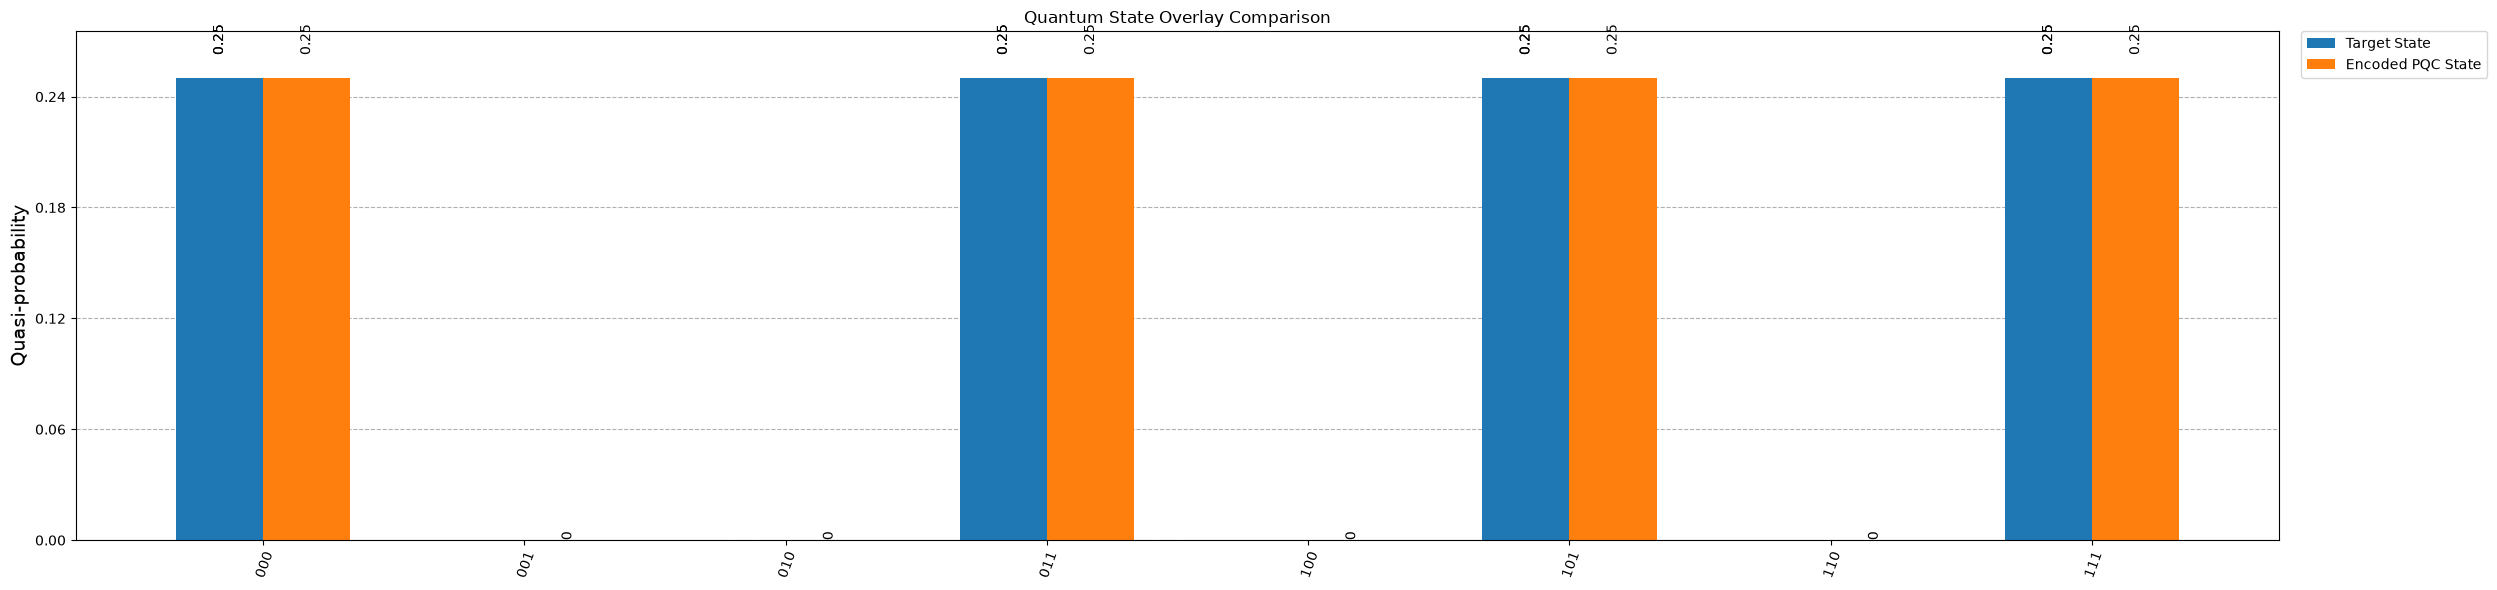


TARGET STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.500                   +0.000                   
1                        +0.000                   +0.500                   
2                        +0.000                   +0.500                   
3                        +0.000                   +0.500                   

ENCODED STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.500                   +0.000                   
1                        +0.000                   +0.500                   
2                        +0.000                   +0.500                   
3                        -0.000                   +0.500                   

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000> : (0.5002913457264093+0j)
|001> : (0.000196865924202419+0j)
|010> : (0.0004156742180555136+0j)
|011> : (0.4999419570548583+0j)
|100> : (0.0003628838209935019+0j)
|101> : (0.49983170473436184+0j)
|110> : (-0.0003141380375620337+0j)
|111> : (0.4999344297016726+0j)


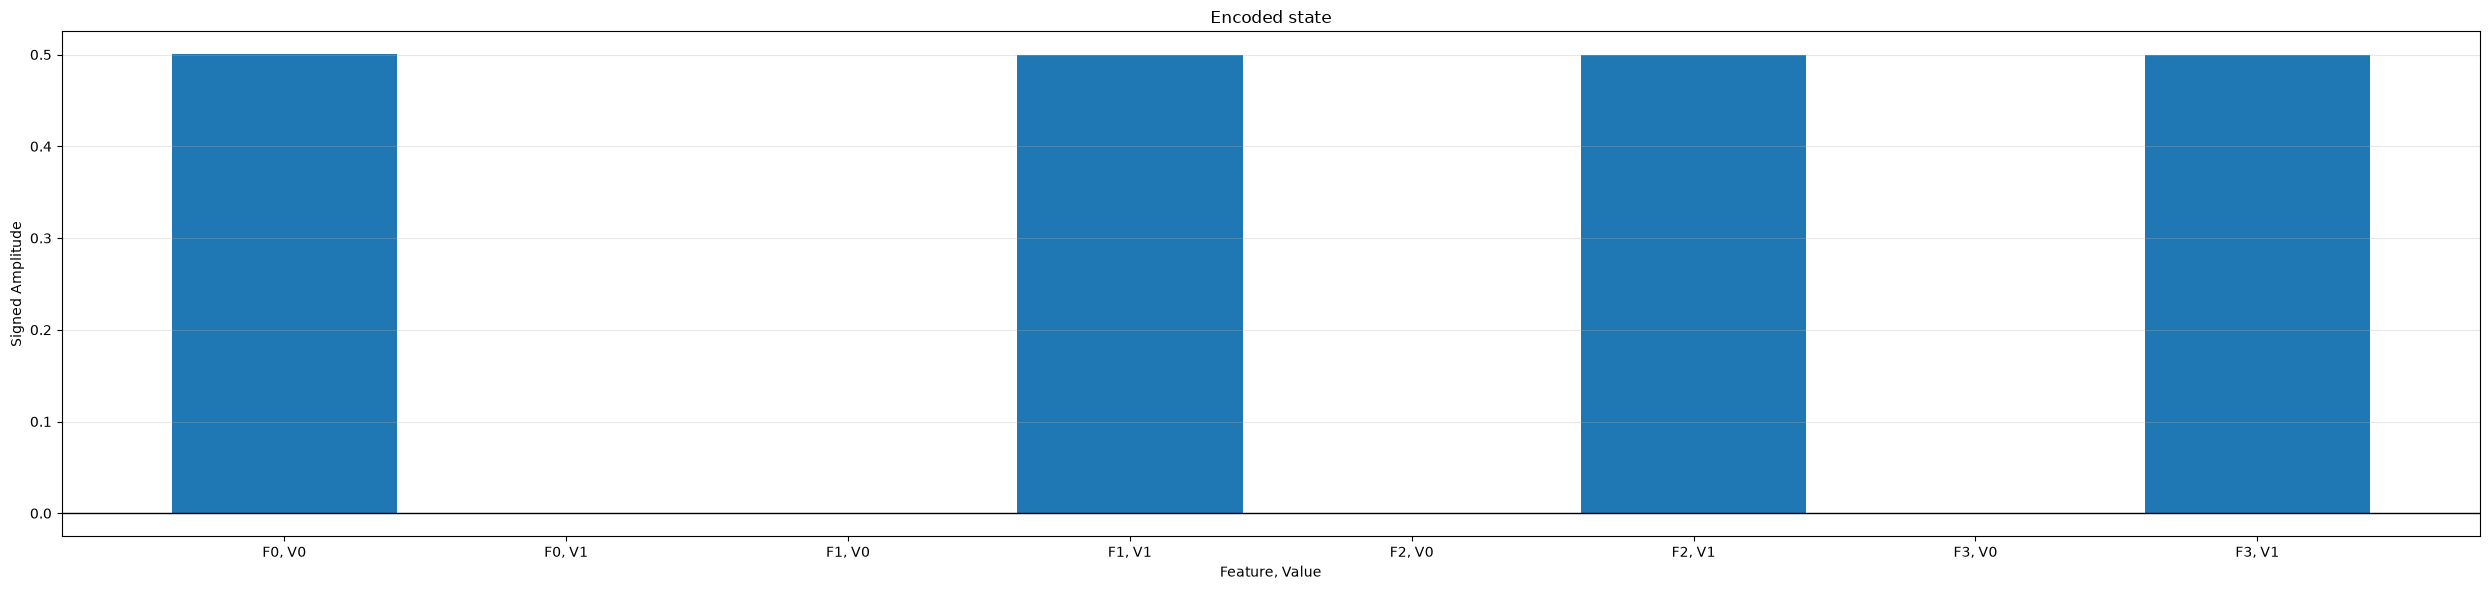


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


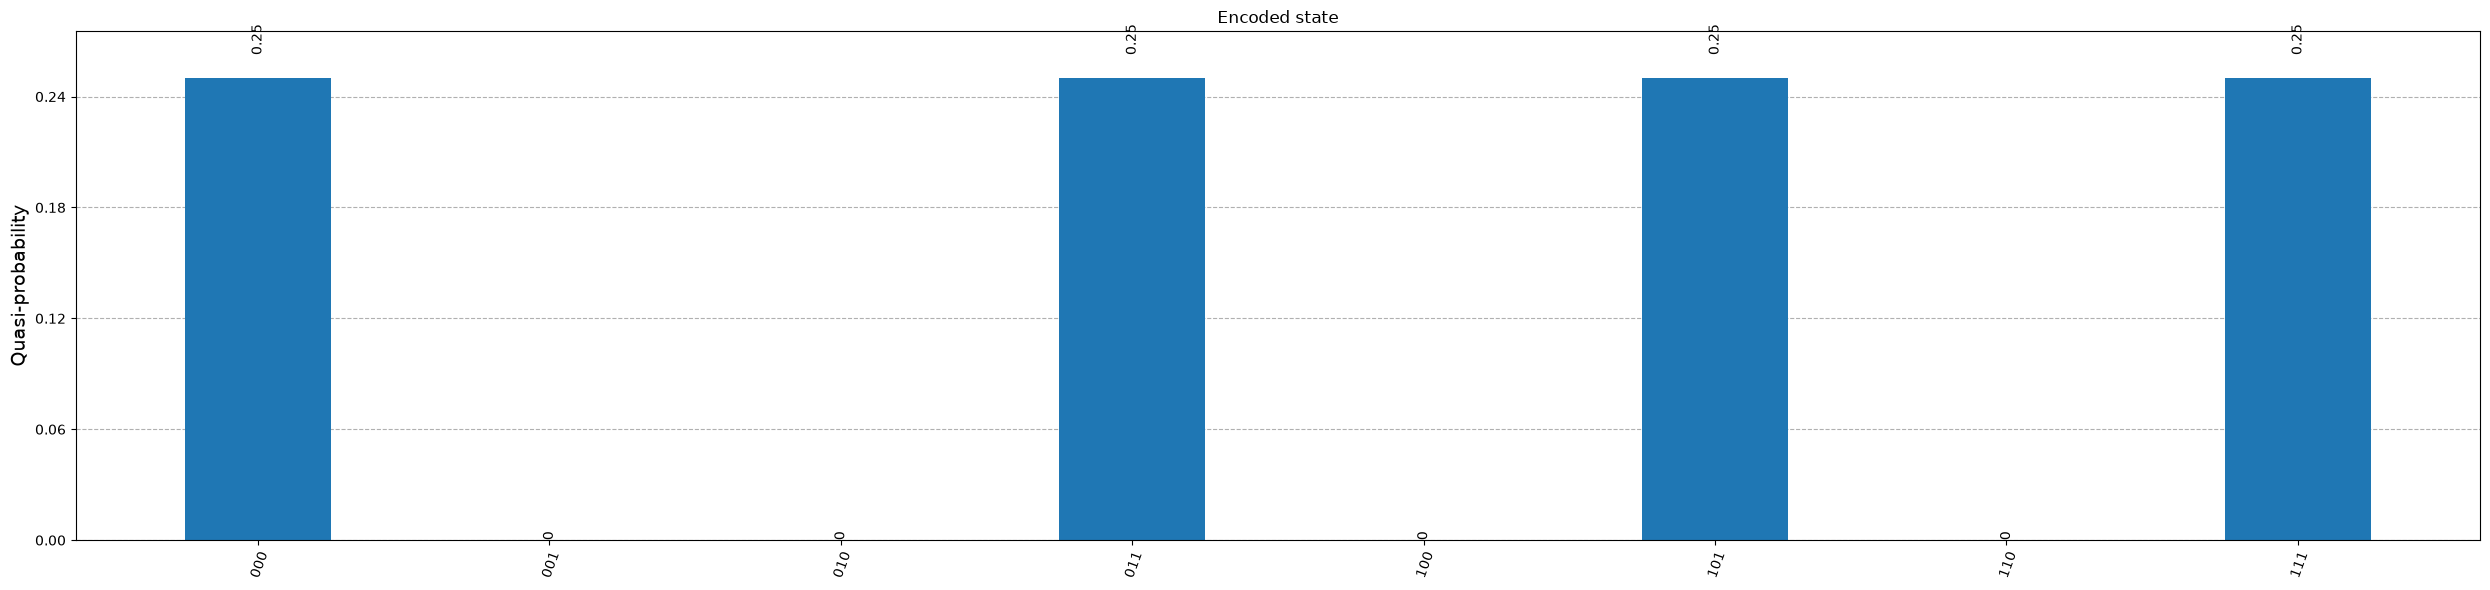

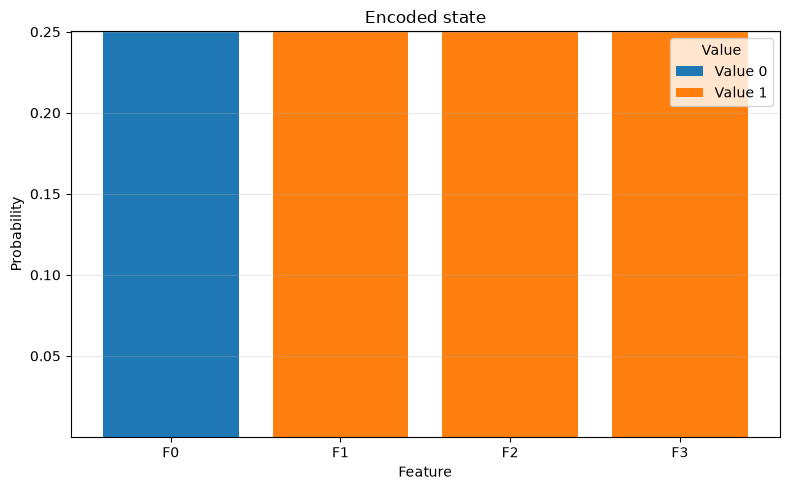


Encoded state
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.500                   +0.000                   
1                        +0.000                   +0.500                   
2                        +0.000                   +0.500                   
3                        -0.000                   +0.500                   


In [14]:
B_parameters_neqr_fidelity, _ = encoder.generate_encoding(query, scheme="NEQR", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.1, loss_function_type="FIDELITY")

## <u>**U operation**</u>

U = (B† ⊗ I_I) A

In [15]:
n_index_q = math.ceil(math.log2(len(dataset)))
n_feature_q = math.ceil(math.log2(len(dataset[0])))

max_value = int(np.max(dataset))
n_value_q = max(1, math.ceil(math.log2(max_value + 1)))
print("Index qubits = ", n_index_q)
print("Feature qubits = ", n_feature_q)
print("Value qubits = ", n_value_q)

Index qubits =  4
Feature qubits =  2
Value qubits =  1


In [16]:
A = encoder.pqc(A_parameters, depth=pqc_depth_for_dataset_encoder, n_qubits=(n_index_q + n_feature_q + n_value_q))

In [17]:
B = encoder.pqc(B_parameters_neqr_fidelity, depth=pqc_depth_for_query_encoder, n_qubits=(n_value_q + n_feature_q))


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (1+0j)


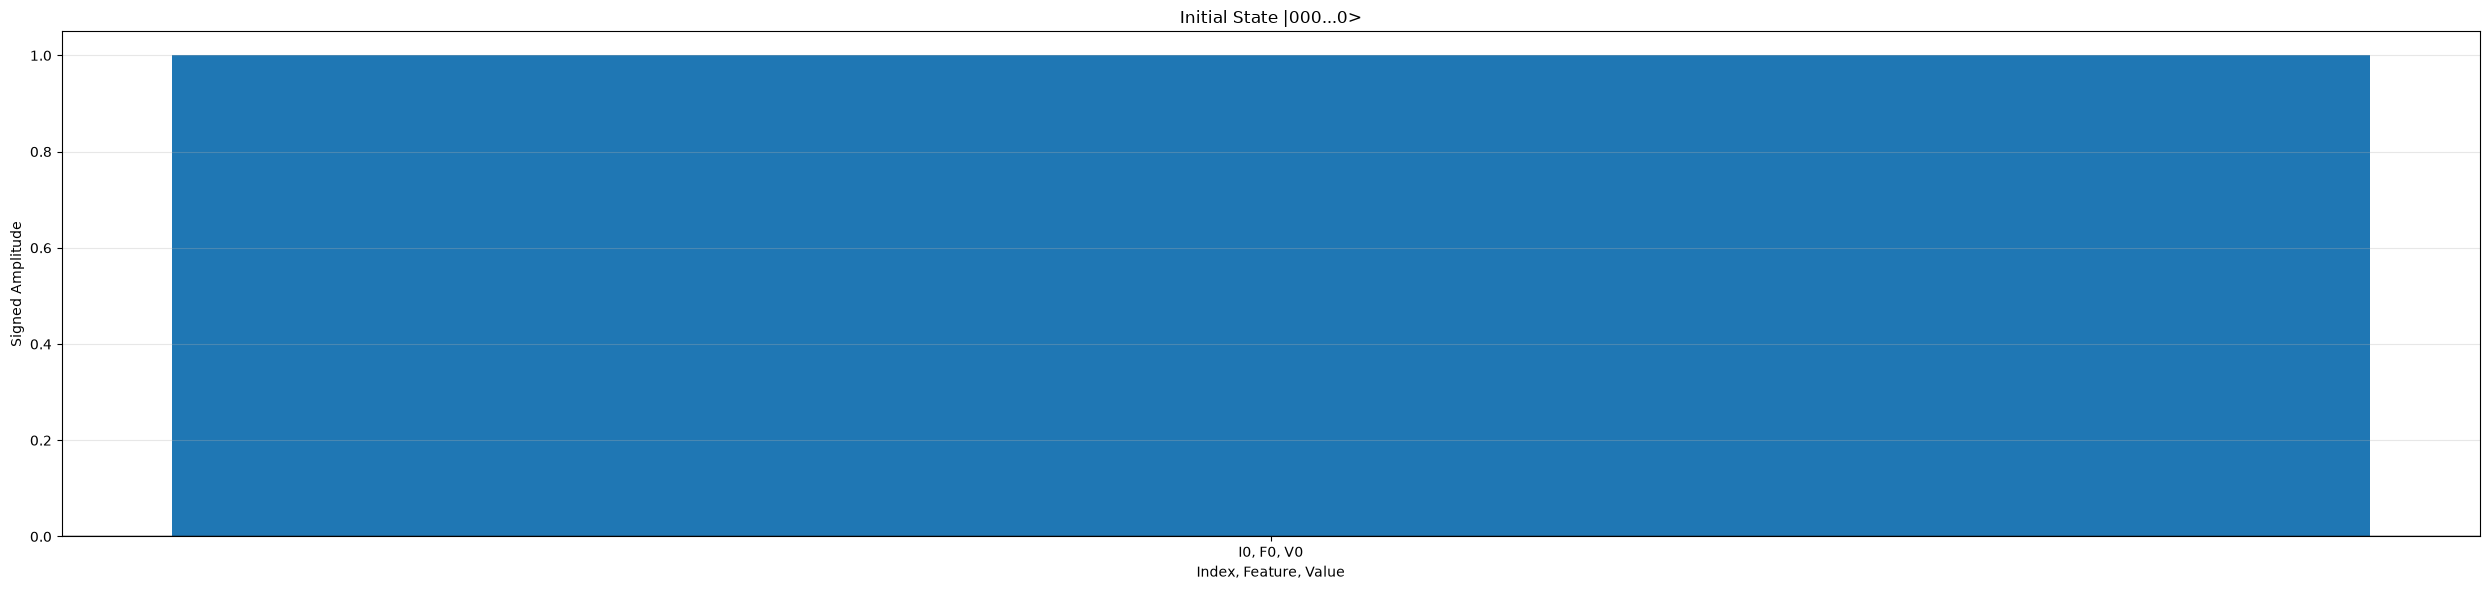


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


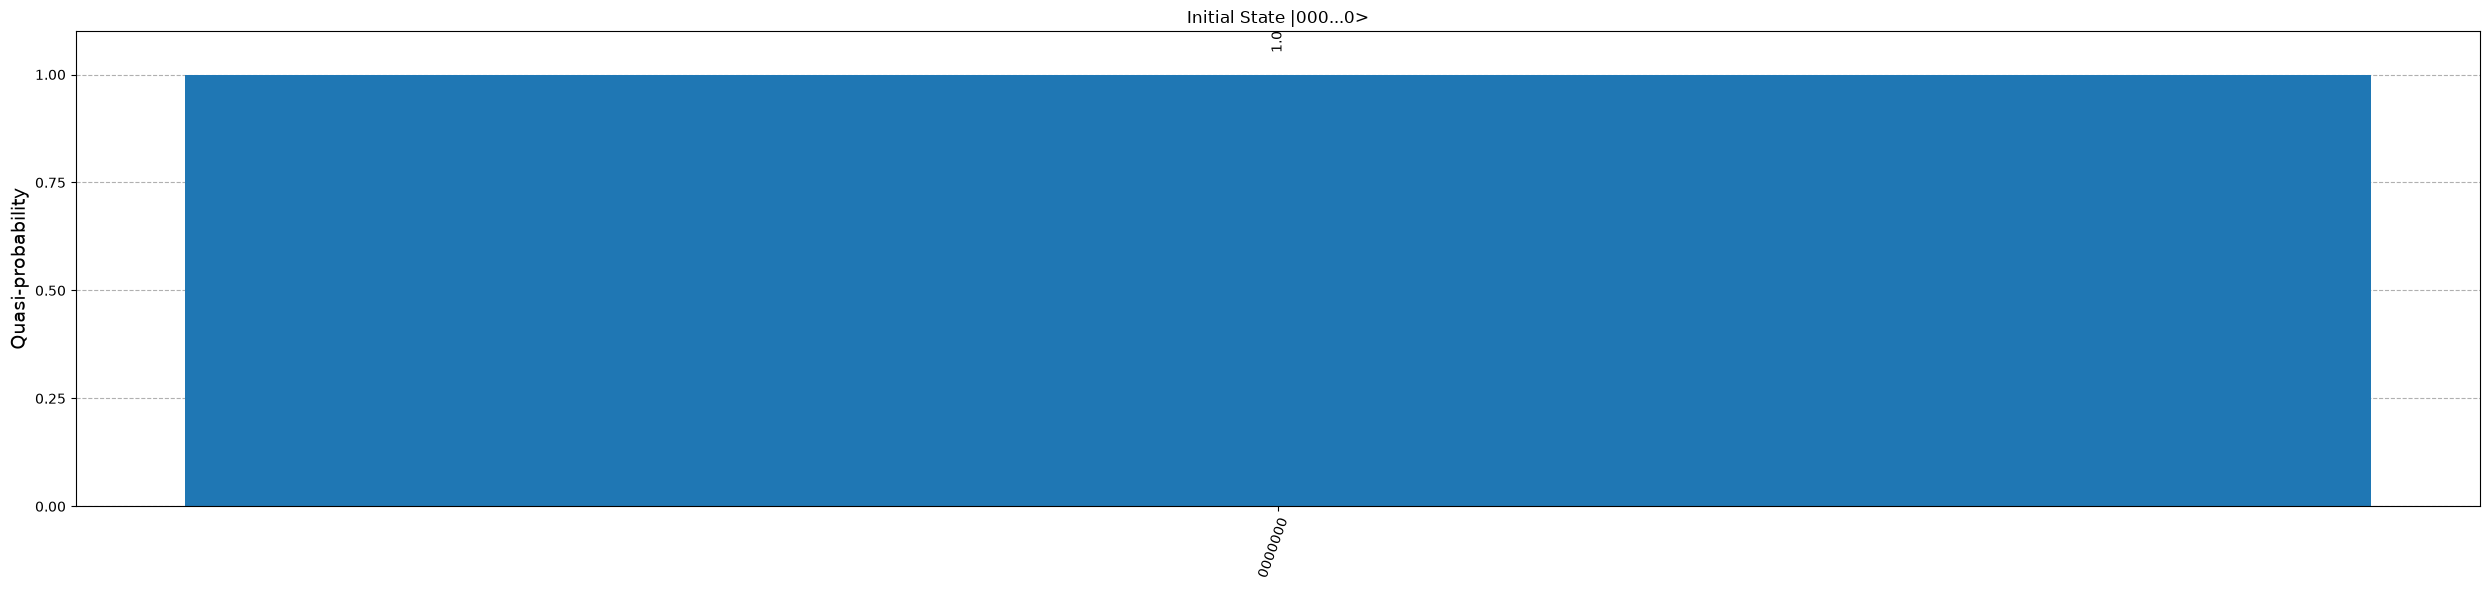

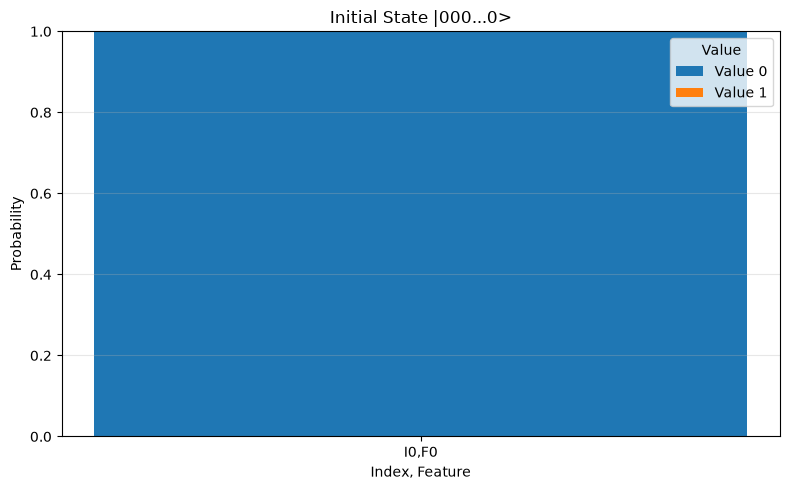


Initial State |000...0>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +1.000                   +0.000                   


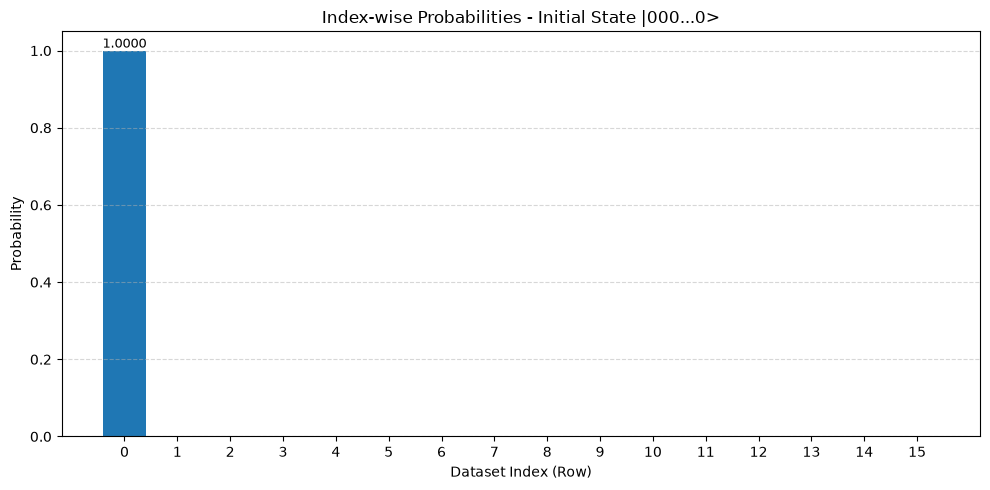

In [18]:
value_reg = QuantumRegister(n_value_q, "Value")
feature_reg = QuantumRegister(n_feature_q, "Feature")
index_reg = QuantumRegister(n_index_q, "Index")
qc = QuantumCircuit(value_reg, feature_reg, index_reg)

initial_state = Statevector.from_instruction(qc)
state_analysis(initial_state, "Initial State |000...0>", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.12478728141236196+0j)
|0000001> : (0.008426885619619517+0j)
|0000010> : (0.11724378785318063+0j)
|0000011> : (0.005190006285570087+0j)
|0000100> : (0.11449309281612483+0j)
|0000101> : (0.0031666824476821944+0j)
|0000110> : (0.11724966363596341+0j)
|0000111> : (0.008607229342835414+0j)
|0001000> : (0.11175479712098015+0j)
|0001001> : (0.008560249306057106+0j)
|0001010> : (0.128281971018368+0j)
|0001011> : (0.014428532395643815+0j)
|0001100> : (0.13070427290153544+0j)
|0001101> : (-0.004064959063485212+0j)
|0001110> : (0.0021890042669060004+0j)
|0001111> : (0.12215618172090666+0j)
|0010000> : (0.13195945560555292+0j)
|0010001> : (0.0015404814644255744+0j)
|0010010> : (0.12270339739552988+0j)
|0010011> : (0.0030087629431228284+0j)
|0010100> : (-0.01146678876470425+0j)
|0010101> : (0.13582865278038272+0j)
|0010110> : (0.12687954454865064+0j)
|0010111> : (-0.009046980955300567+0j)
|0011000> : (0.12240152914293183+0j)
|0011001> : (0.00450741140952

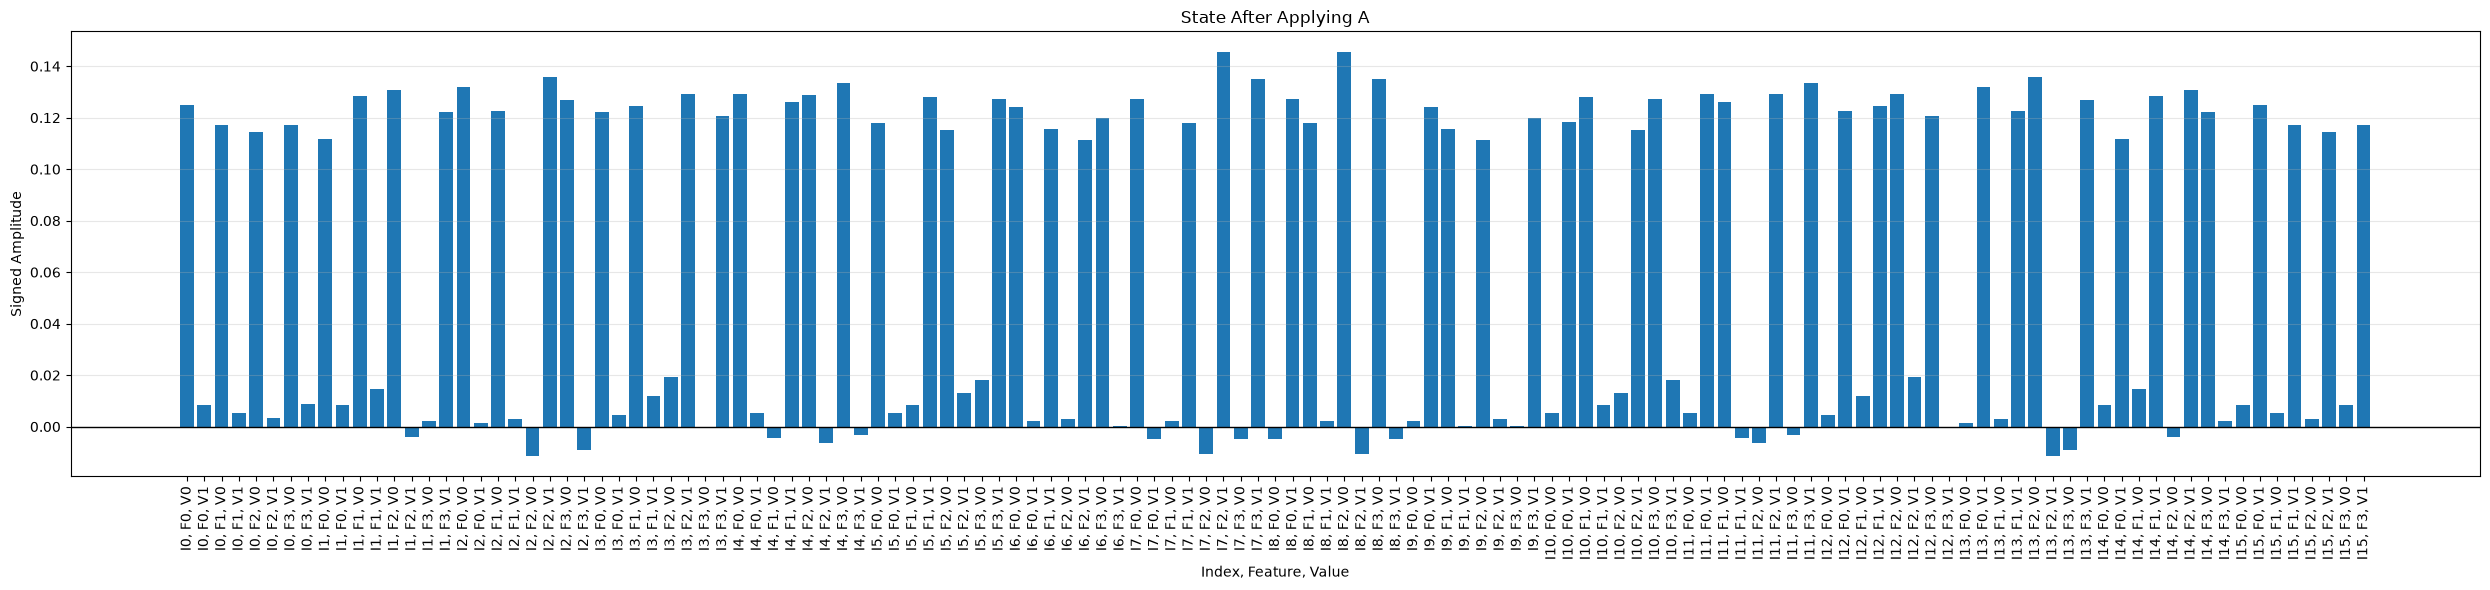


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


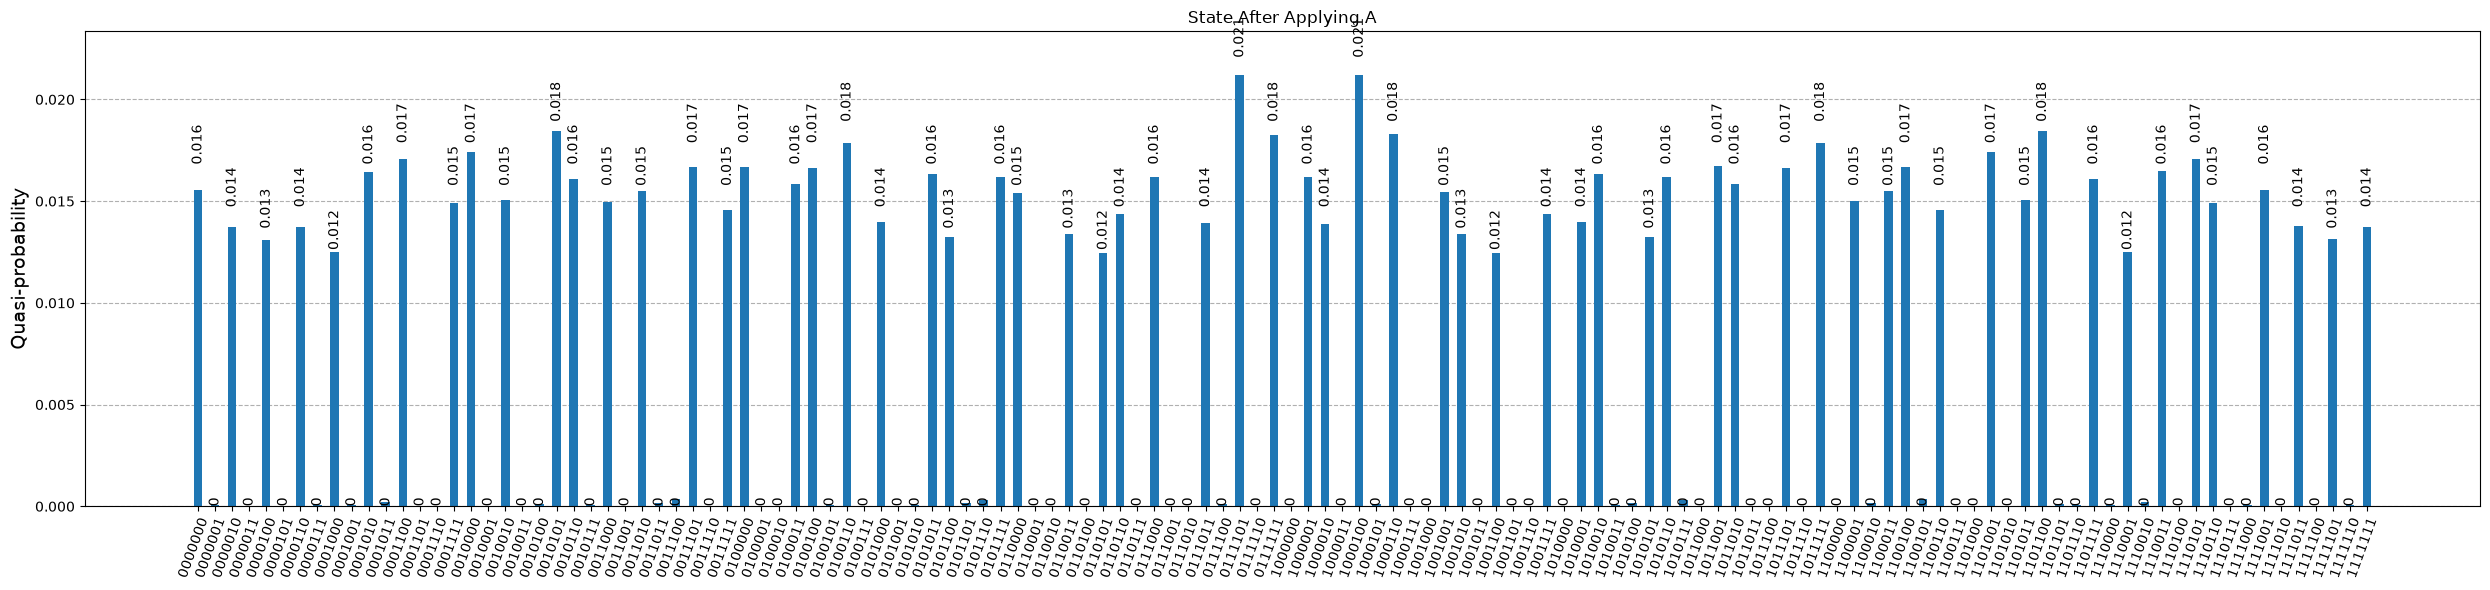

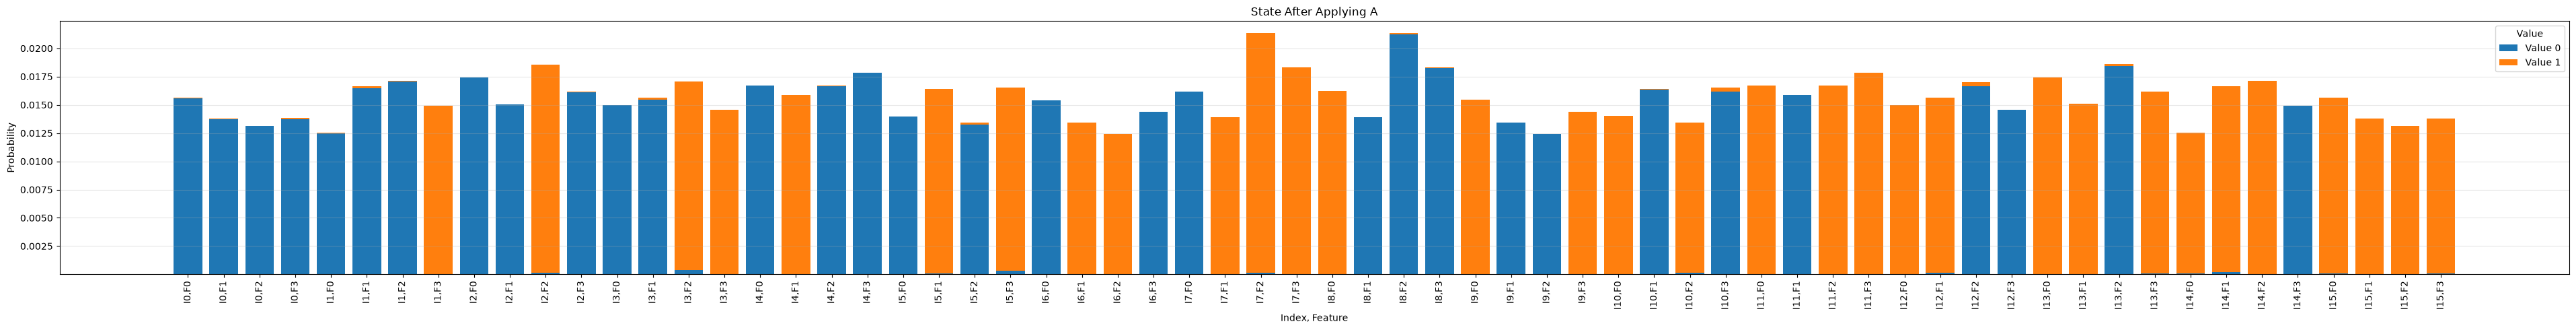


State After Applying A
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.008                   
0                        1                        +0.117                   +0.005                   
0                        2                        +0.114                   +0.003                   
0                        3                        +0.117                   +0.009                   
1                        0                        +0.112                   +0.009                   
1                        1                        +0.128                   +0.014                   
1                        2                        +0.131                   -0.004                   
1                        3                        +0.002           

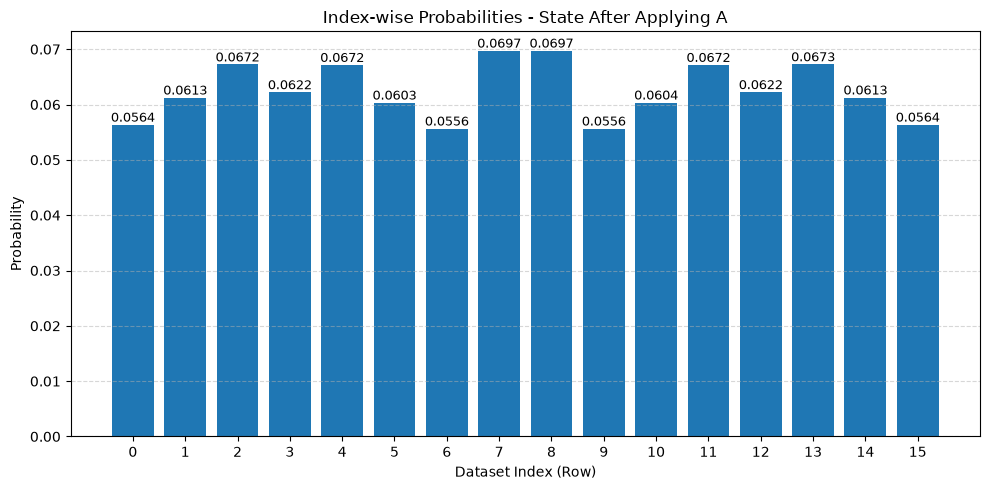

In [19]:
qc.compose(A, inplace=True)
qc.barrier()

state_after_A = Statevector.from_instruction(qc)
state_analysis(state_after_A, "State After Applying A", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.0709656667240874+0j)
|0000001> : (-0.007796070818392515+0j)
|0000010> : (-0.18911416496639116+0j)
|0000011> : (-0.12072395792506069+0j)
|0000100> : (-0.01587701548692249+0j)
|0000101> : (0.025847441275635822+0j)
|0000110> : (-0.0004961116348565864+0j)
|0000111> : (-0.0006497762095543639+0j)
|0001000> : (0.12226342373699353+0j)
|0001001> : (0.0120237268767001+0j)
|0001010> : (-0.12908949071325343+0j)
|0001011> : (-0.07456743468110531+0j)
|0001100> : (-0.009582435886602328+0j)
|0001101> : (0.12817099180826022+0j)
|0001110> : (0.042182795366203084+0j)
|0001111> : (0.07508386204395268+0j)
|0010000> : (0.13089823937072537+0j)
|0010001> : (-0.012396332559508175+0j)
|0010010> : (-0.121442247682534+0j)
|0010011> : (-0.09276223516081805+0j)
|0010100> : (-0.09385782678992587+0j)
|0010101> : (-0.013335415765189025+0j)
|0010110> : (-0.11324611432092596+0j)
|0010111> : (-0.06920366280805666+0j)
|0011000> : (0.19212839144173818+0j)
|0011001> : (0.00826348

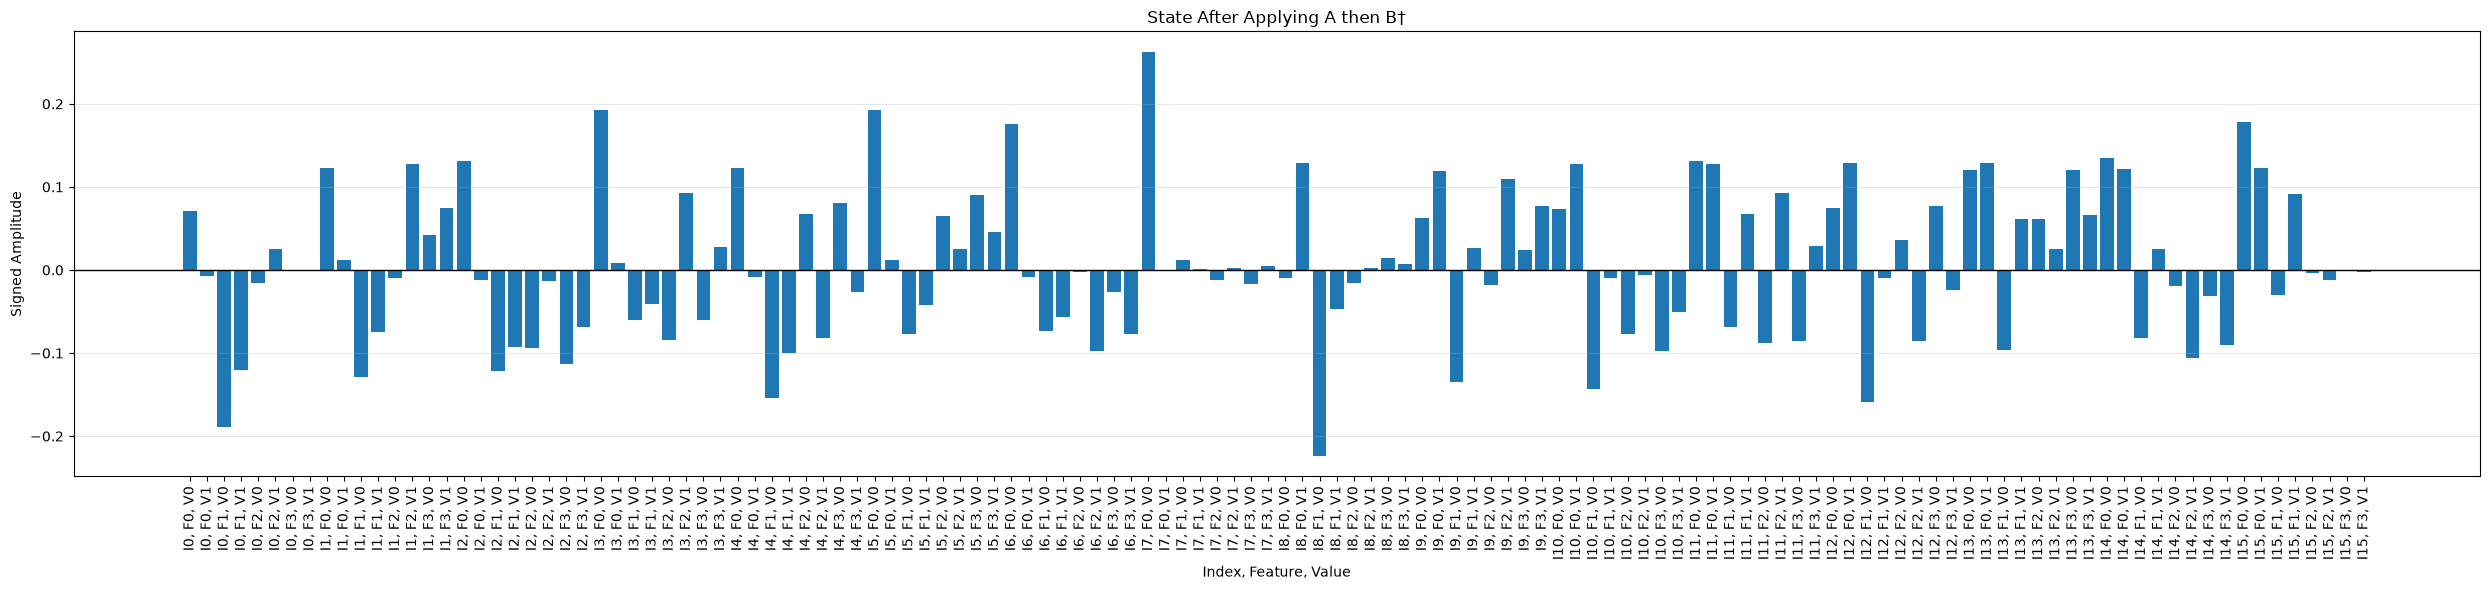


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


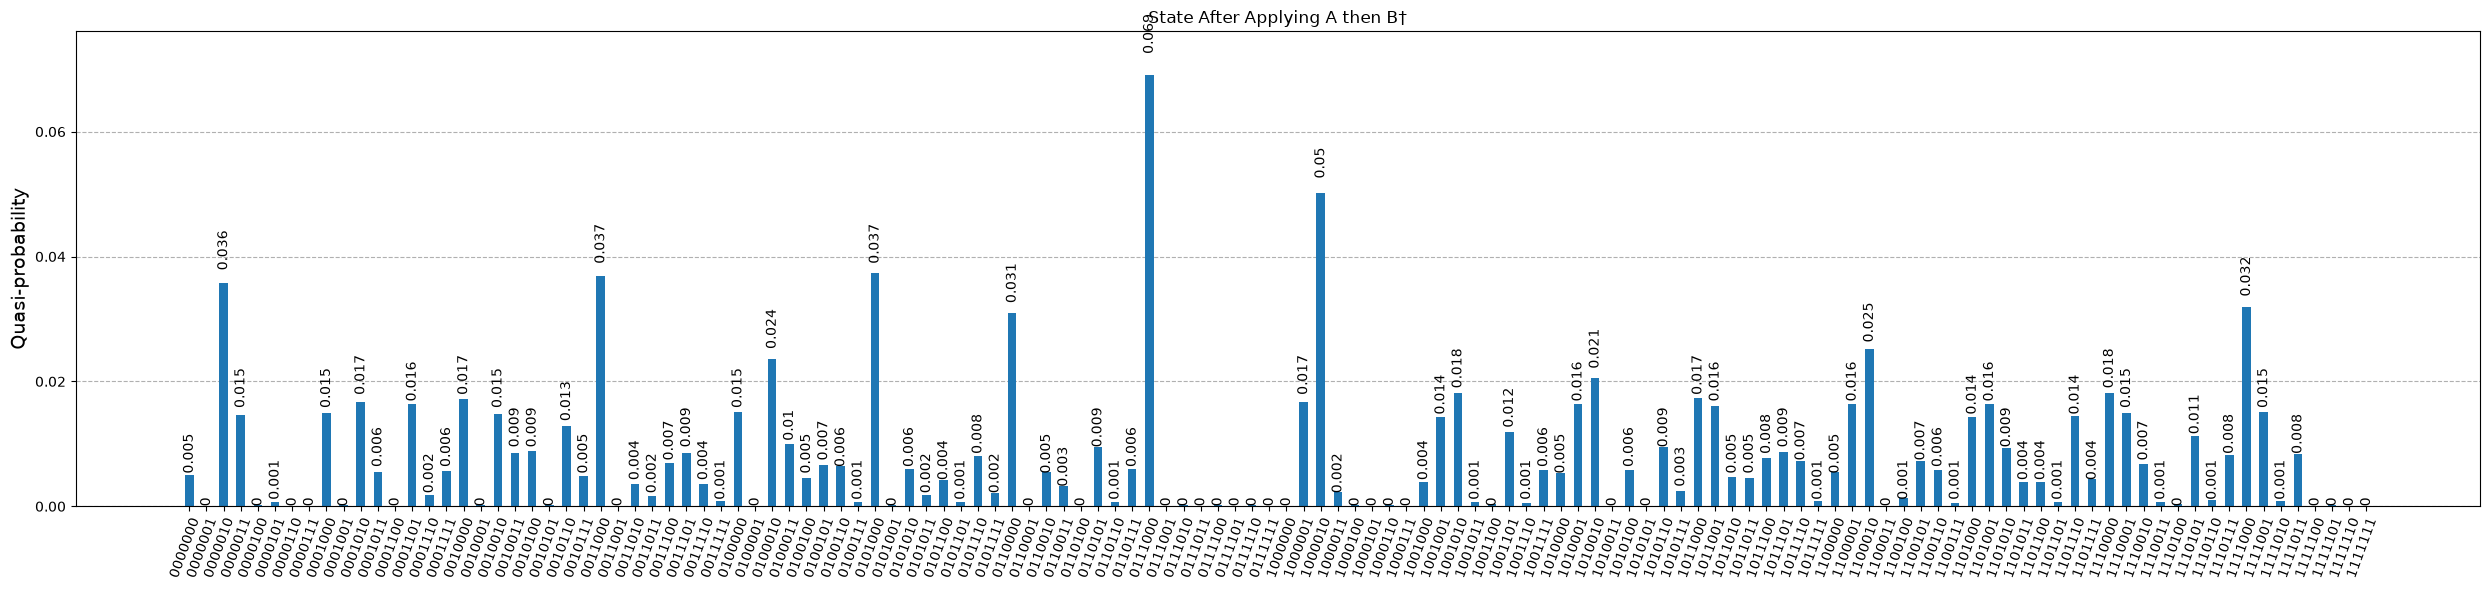

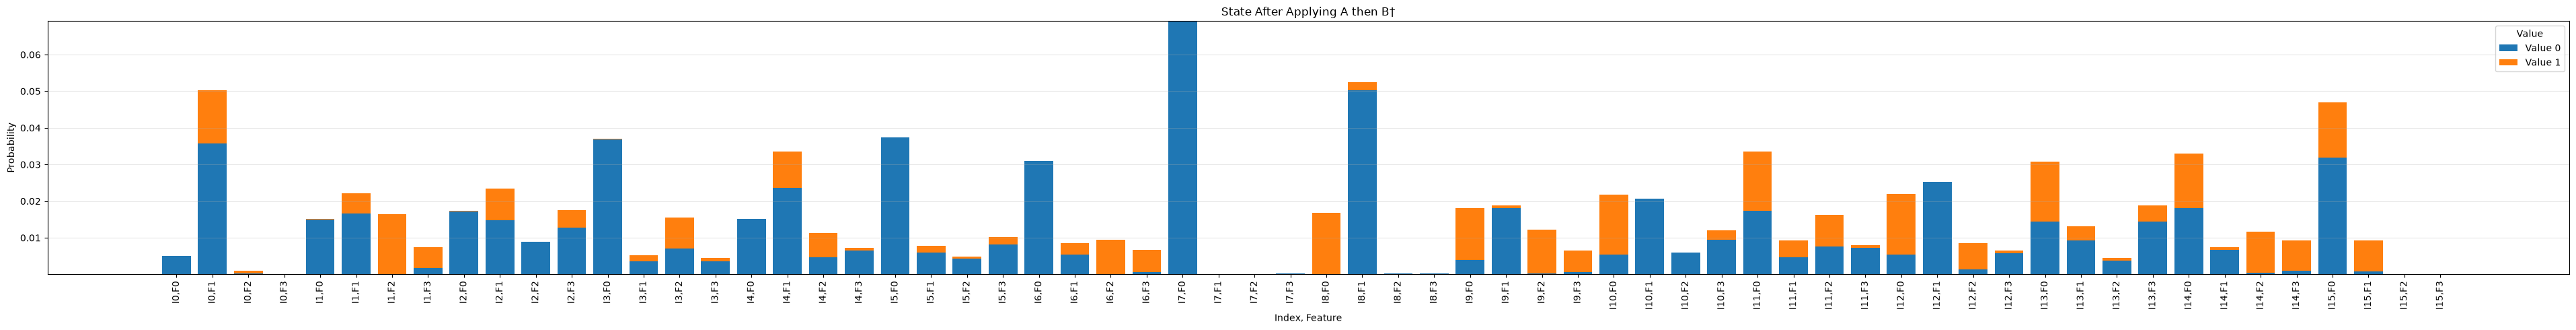


State After Applying A then B†
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.071                   -0.008                   
0                        1                        -0.189                   -0.121                   
0                        2                        -0.016                   +0.026                   
0                        3                        -0.000                   -0.001                   
1                        0                        +0.122                   +0.012                   
1                        1                        -0.129                   -0.075                   
1                        2                        -0.010                   +0.128                   
1                        3                        +0.042   

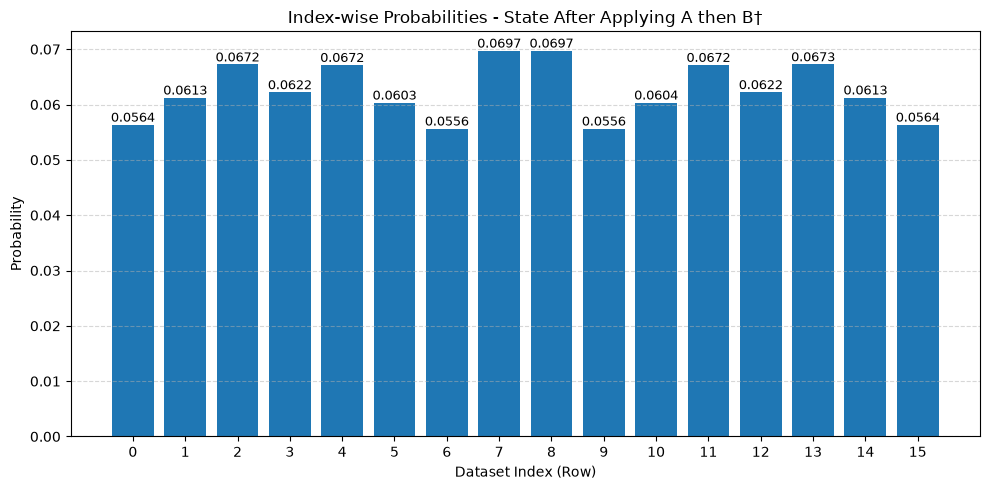

In [20]:
qc.compose(B.inverse(), qubits=range(n_feature_q + n_value_q), inplace=True)
qc.barrier()

state_after_B_inverse = Statevector.from_instruction(qc)
state_analysis(state_after_B_inverse, "State After Applying A then B†", n_value_q, n_feature_q, n_index_q)

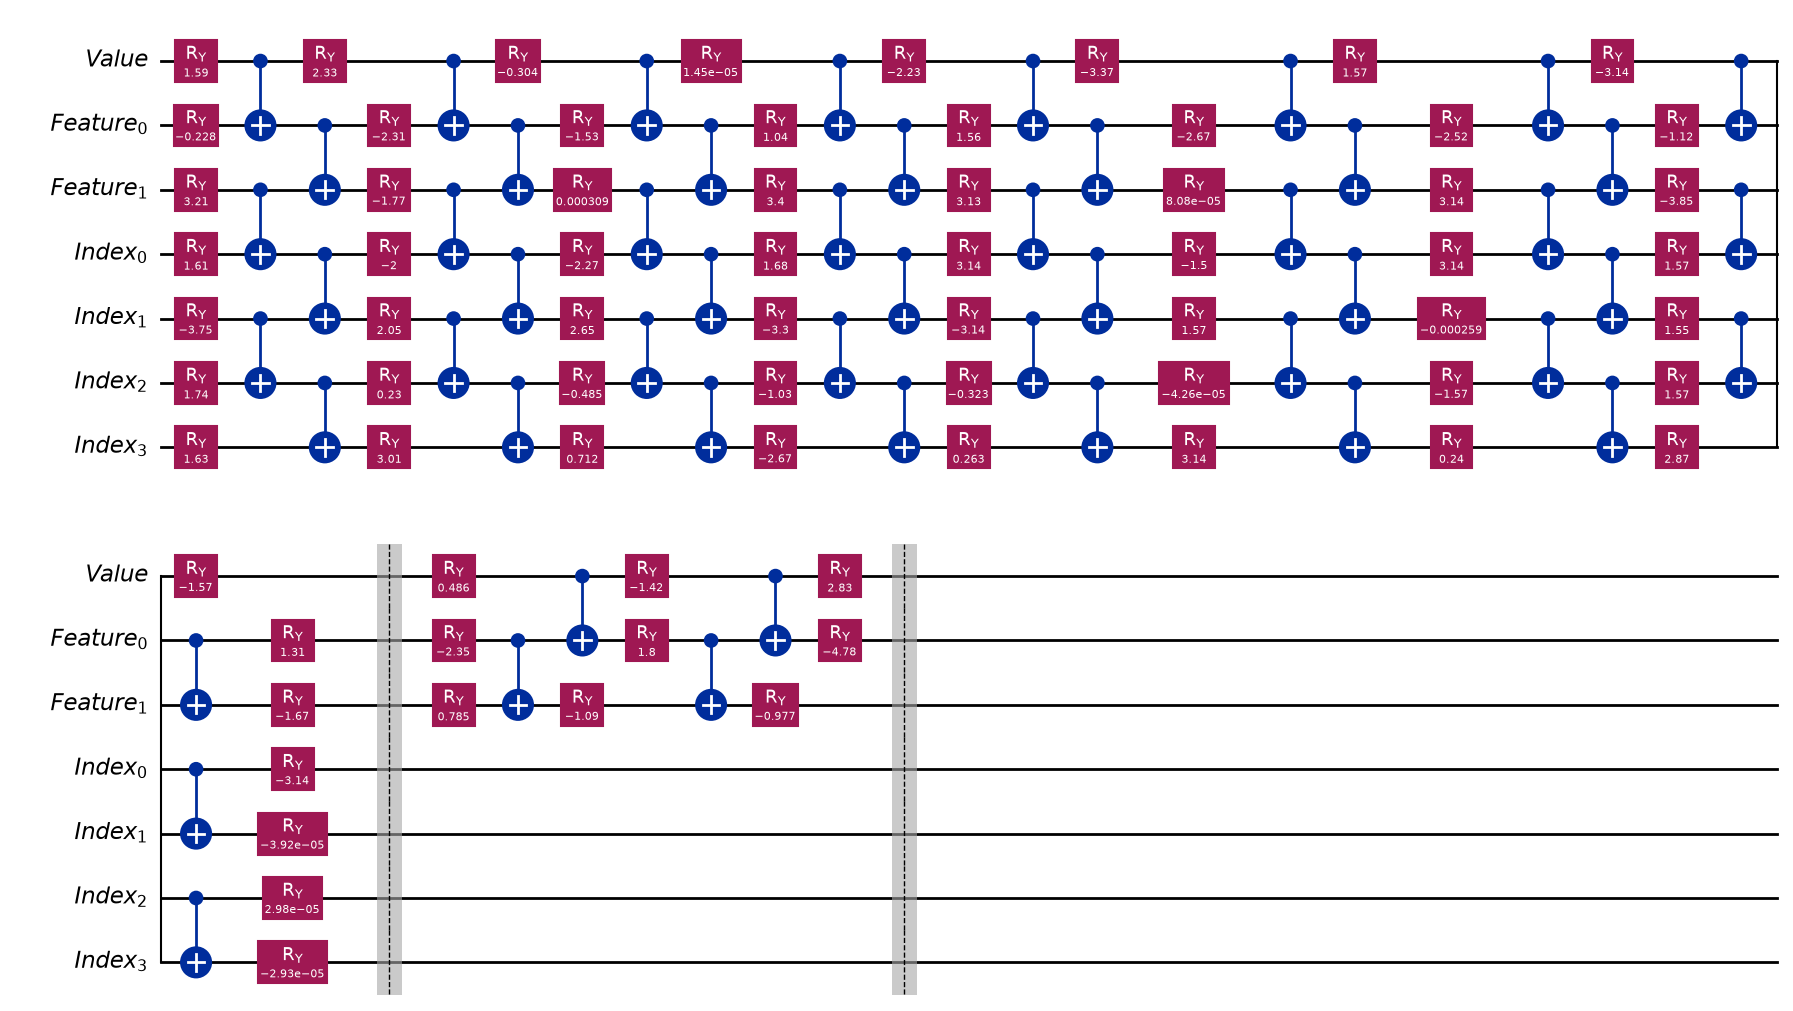

In [21]:
display(qc.draw("mpl"))

# <u>**Part 2: Use Grover Search for Image Matching**</u>

In [22]:
try:
    A_saved = load_parameters(scheme="NEQR", loss_function_type="FIDELITY")

    A_saved_parameters = A_saved["parameters"]
    A_saved_best_fidelity = A_saved["fidelity"]

    print(f"Loaded saved dataset encoder. Fidelity = {A_saved_best_fidelity:.3f}")

except (ValueError, KeyError, OSError) as e:
    print(f"Could not reuse saved dataset enocder. Train again.")

Loaded saved dataset encoder. Fidelity = 0.992


In [23]:
A_saved_parameters

array([ 1.58609957e+00, -2.27574416e-01,  3.21353912e+00,  1.60958033e+00,
       -3.74935787e+00,  1.74390525e+00,  1.62805042e+00,  2.33034645e+00,
       -2.31240258e+00, -1.77421663e+00, -1.99713242e+00,  2.04710865e+00,
        2.30006556e-01,  3.01022153e+00, -3.04404904e-01, -1.53443570e+00,
        3.08570597e-04, -2.27293484e+00,  2.64871492e+00, -4.85090296e-01,
        7.12050611e-01,  1.44824998e-05,  1.03756077e+00,  3.40303201e+00,
        1.67924875e+00, -3.30216068e+00, -1.03466238e+00, -2.66869432e+00,
       -2.23473035e+00,  1.55656019e+00,  3.13310310e+00,  3.14159983e+00,
       -3.14160250e+00, -3.22896398e-01,  2.63120945e-01, -3.36880509e+00,
       -2.66730177e+00,  8.08334034e-05, -1.50360801e+00,  1.57092413e+00,
       -4.25707159e-05,  3.14162178e+00,  1.57090091e+00, -2.52241238e+00,
        3.14144983e+00,  3.14180383e+00, -2.59327506e-04, -1.57084454e+00,
        2.40144017e-01, -3.14140300e+00, -1.11549838e+00, -3.84592965e+00,
        1.57064866e+00,  

In [24]:
GS = GroverSearch()

## <u>**GS with NEQR scheme and FIDELITY cost function**</u>

Number of data elements =  16
Number of features =  4
Index qubits =  4
Data qubits =  2
Value qubits =  1
Total no of qubits =  7
Range of value qubits =  [0]
Range of feature qubits =  [1, 2]
Range of index qubits =  [3, 4, 5, 6]

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (0.0709656667240874+0j)
|0000001> : (-0.007796070818392515+0j)
|0000010> : (-0.18911416496639116+0j)
|0000011> : (-0.12072395792506069+0j)
|0000100> : (-0.01587701548692249+0j)
|0000101> : (0.025847441275635822+0j)
|0000110> : (-0.0004961116348565864+0j)
|0000111> : (-0.0006497762095543639+0j)
|0001000> : (0.12226342373699353+0j)
|0001001> : (0.0120237268767001+0j)
|0001010> : (-0.12908949071325343+0j)
|0001011> : (-0.07456743468110531+0j)
|0001100> : (-0.009582435886602328+0j)
|0001101> : (0.12817099180826022+0j)
|0001110> : (0.042182795366203084+0j)
|0001111> : (0.07508386204395268+0j)
|0010000> : (0.13089823937072537+0j)
|0010001> : (-0.012396332559508175+0j)
|0010010> : (-0.121442247682534+0j)
|0010011> : (-0.09276223516081805+0j)
|0010100> : (-0.09385782678992587+0j)
|0010101> : (-0.013335415765189025+0j)
|0010110> : (-0.11324611432092596+0j)
|0010111> : (-0.06920366280805666+0j)
|0011000> : (0.19212839144173818+0j)
|0011001> : (0.00826348

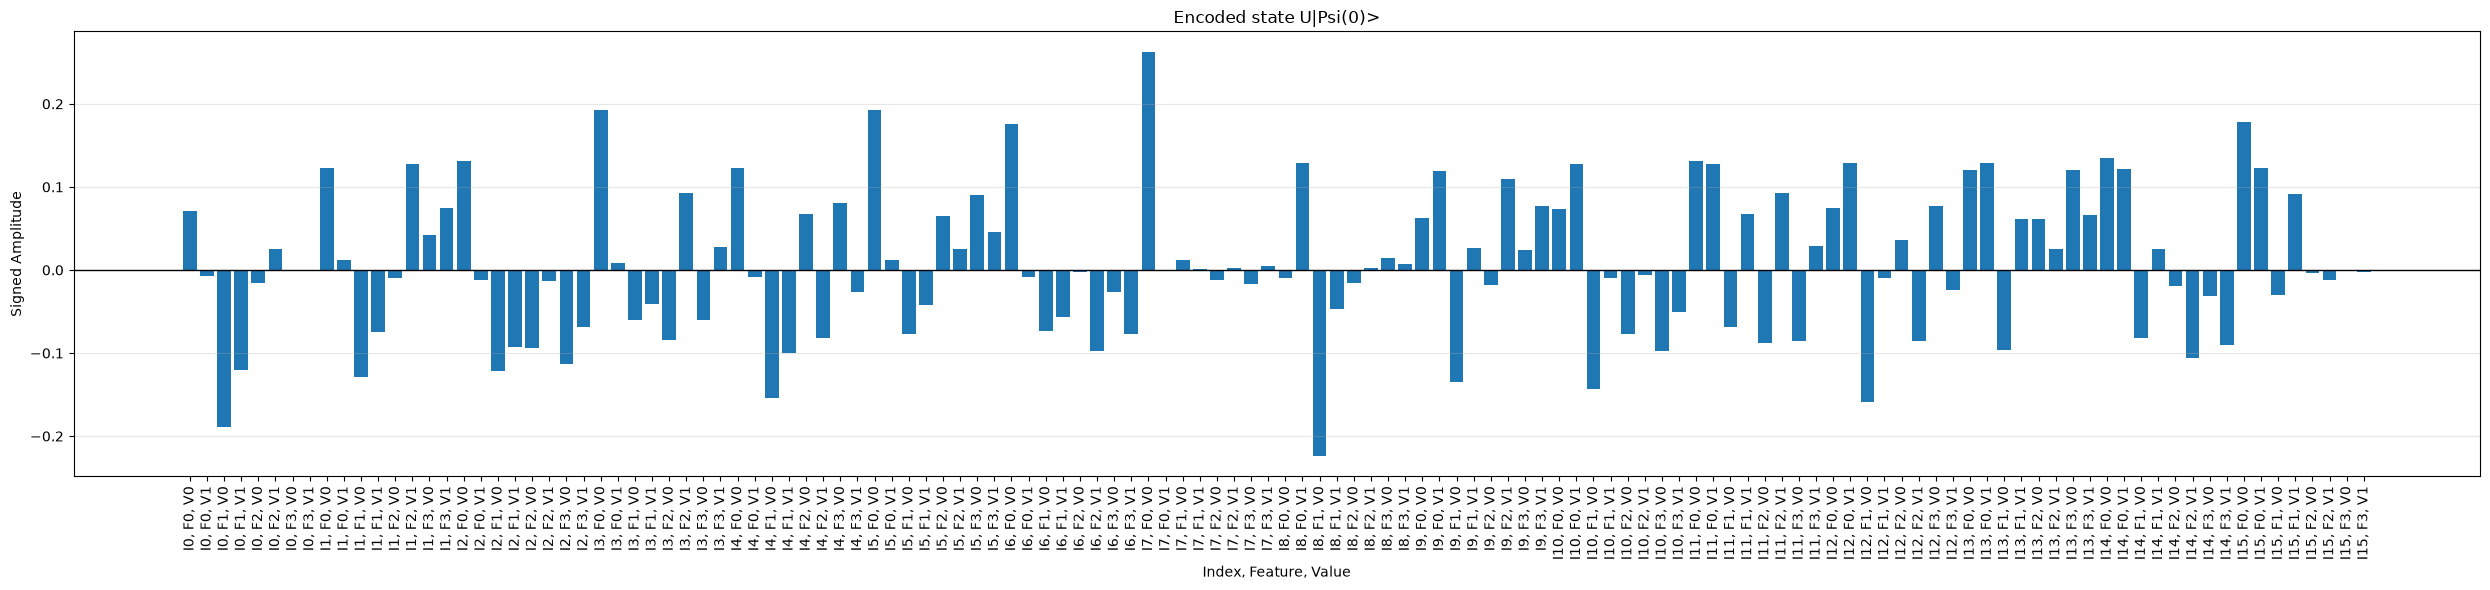


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


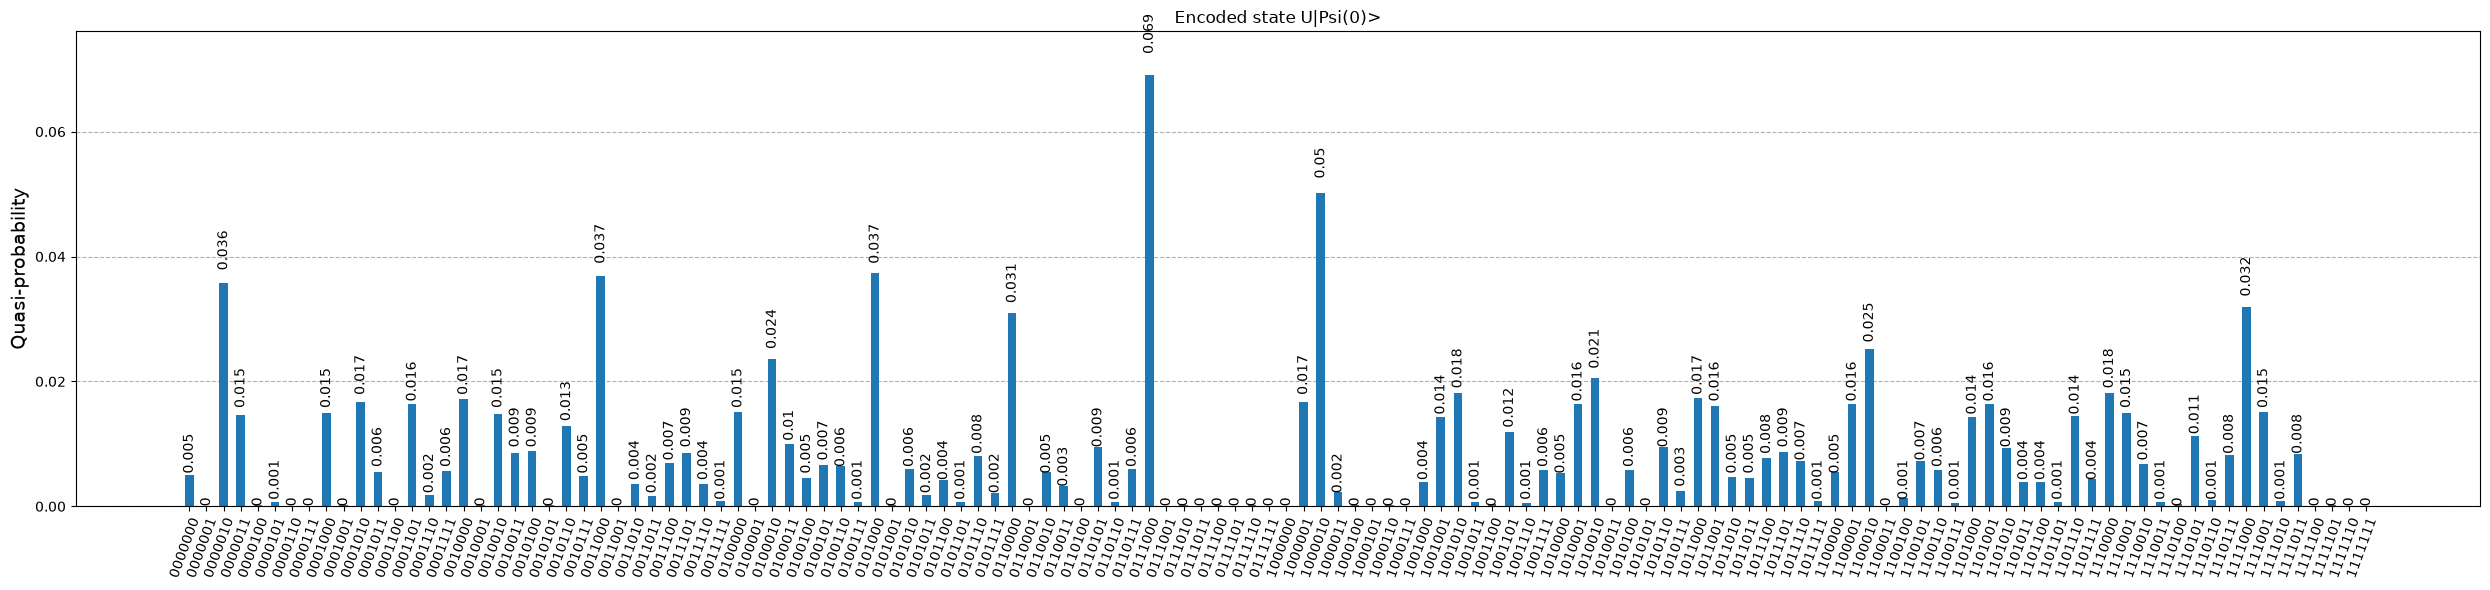

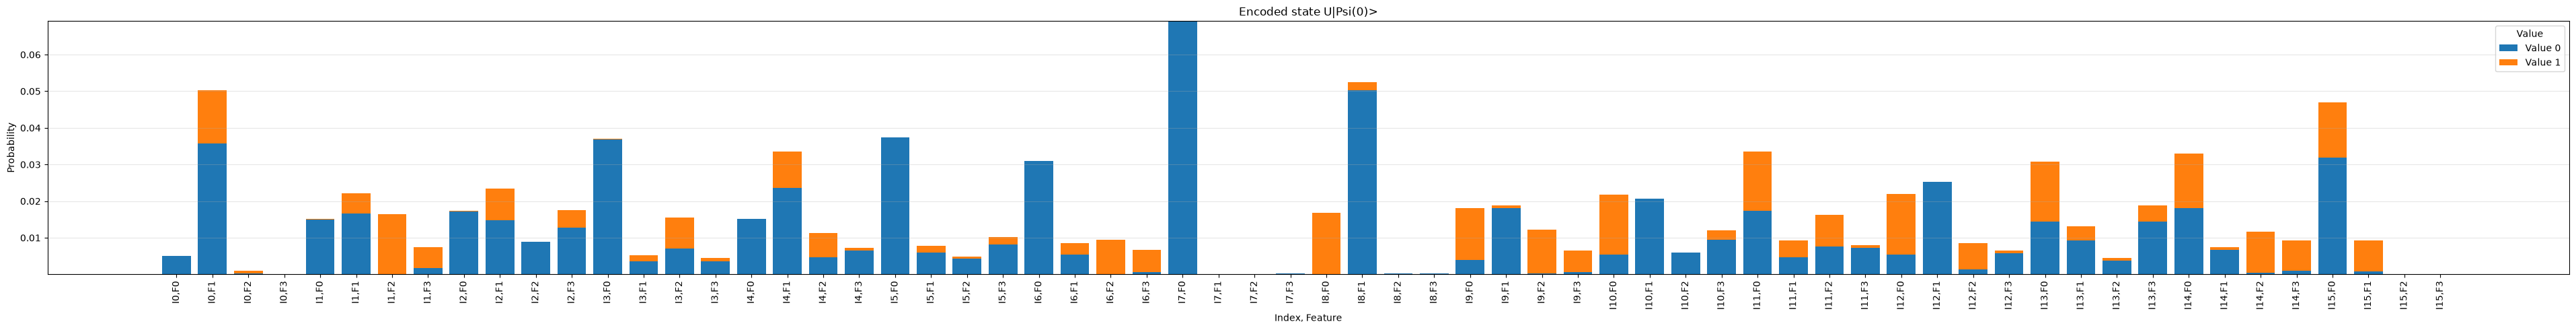


Encoded state U|Psi(0)>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.071                   -0.008                   
0                        1                        -0.189                   -0.121                   
0                        2                        -0.016                   +0.026                   
0                        3                        -0.000                   -0.001                   
1                        0                        +0.122                   +0.012                   
1                        1                        -0.129                   -0.075                   
1                        2                        -0.010                   +0.128                   
1                        3                        +0.042          

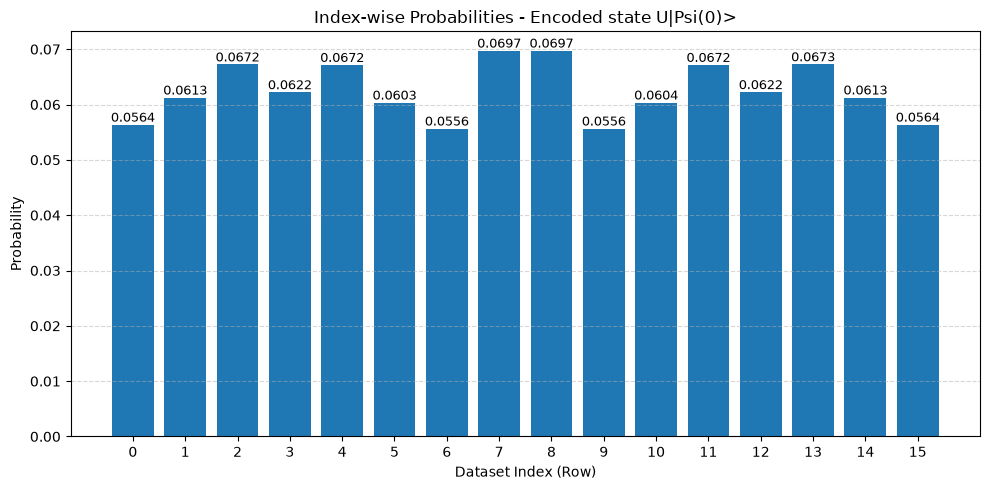




GROVER ITERATION 1


> Oracle: 

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.07096566672408738+0j)
|0000001> : (-0.007796070818392514+0j)
|0000010> : (-0.18911416496639114+0j)
|0000011> : (-0.12072395792506066+0j)
|0000100> : (-0.015877015486922483+0j)
|0000101> : (0.02584744127563582+0j)
|0000110> : (-0.0004961116348565891+0j)
|0000111> : (-0.0006497762095543627+0j)
|0001000> : (-0.12226342373699352+0j)
|0001001> : (0.012023726876700109+0j)
|0001010> : (-0.1290894907132534+0j)
|0001011> : (-0.0745674346811053+0j)
|0001100> : (-0.009582435886602337+0j)
|0001101> : (0.1281709918082602+0j)
|0001110> : (0.04218279536620307+0j)
|0001111> : (0.07508386204395266+0j)
|0010000> : (-0.13089823937072534+0j)
|0010001> : (-0.012396332559508174+0j)
|0010010> : (-0.12144224768253398+0j)
|0010011> : (-0.09276223516081802+0j)
|0010100> : (-0.09385782678992584+0j)
|0010101> : (-0.013335415765189021+0j)
|0010110> : (-0.11324611432092593+0j)
|0010111> : (-0.06920366280805665+0j)
|0011000> : (-0.19212839144173816+0j)
|0011001> : (0.008

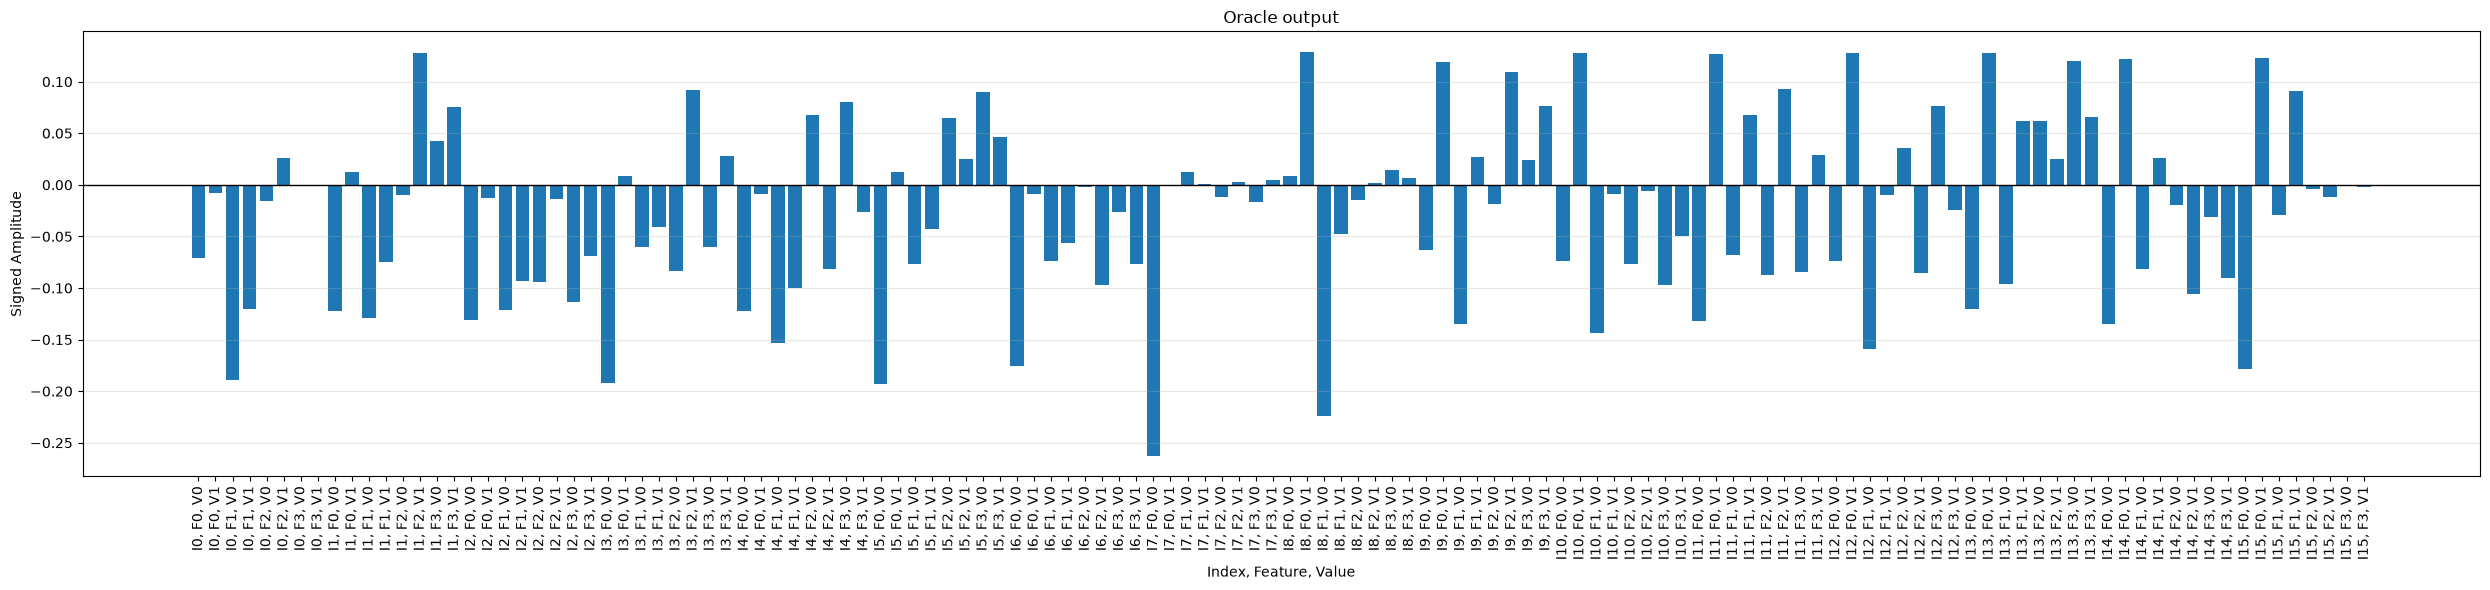


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


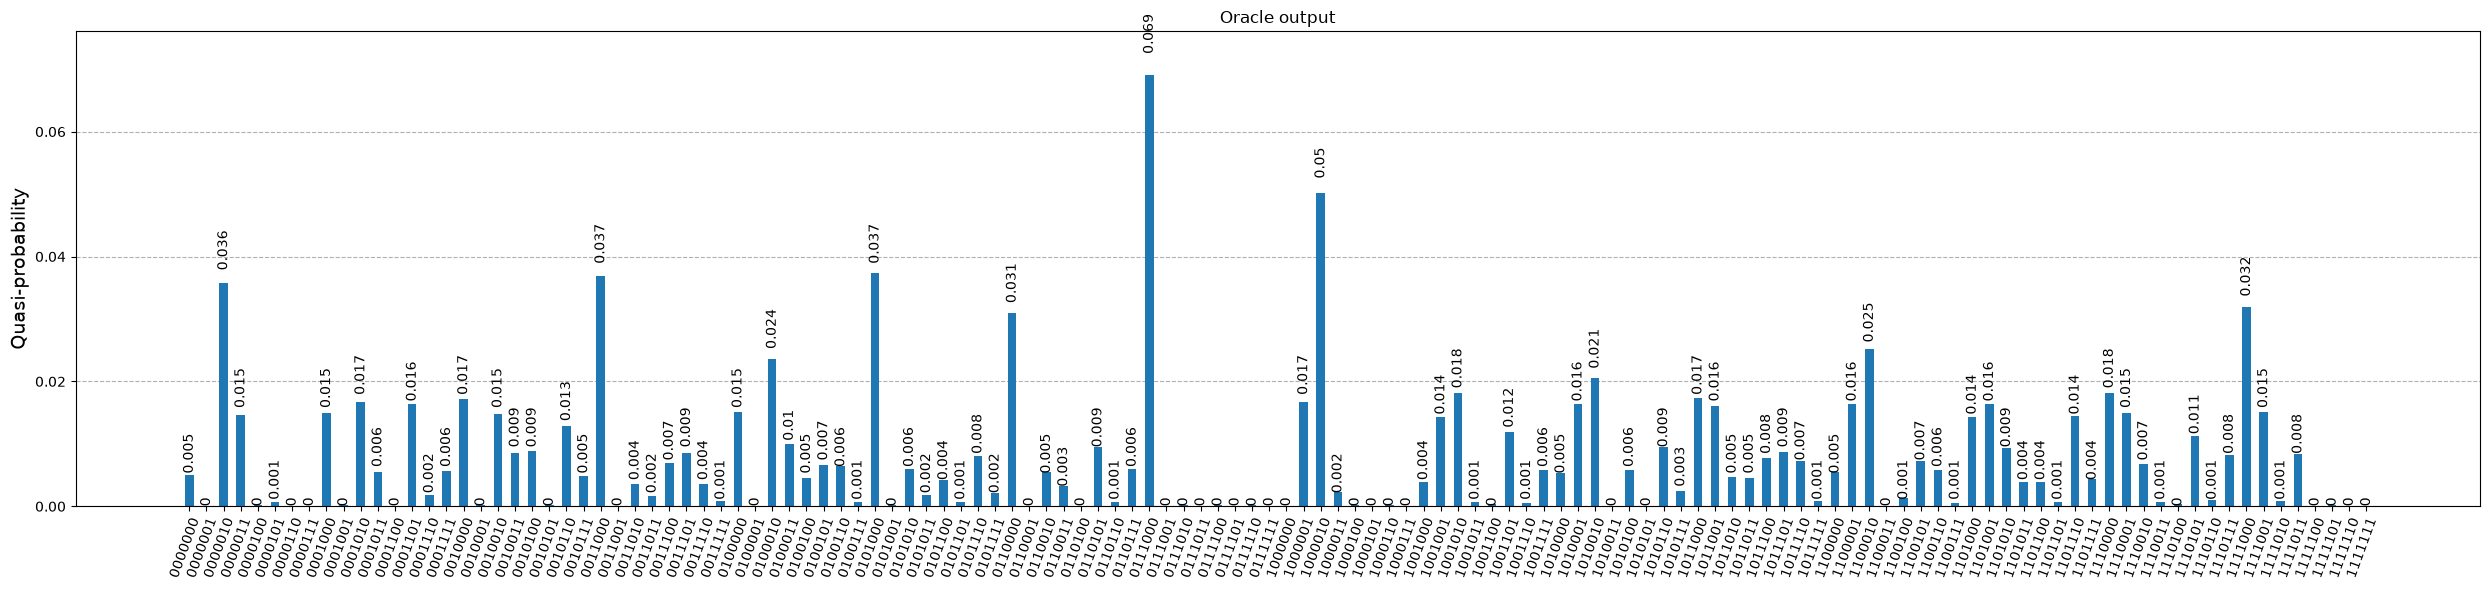

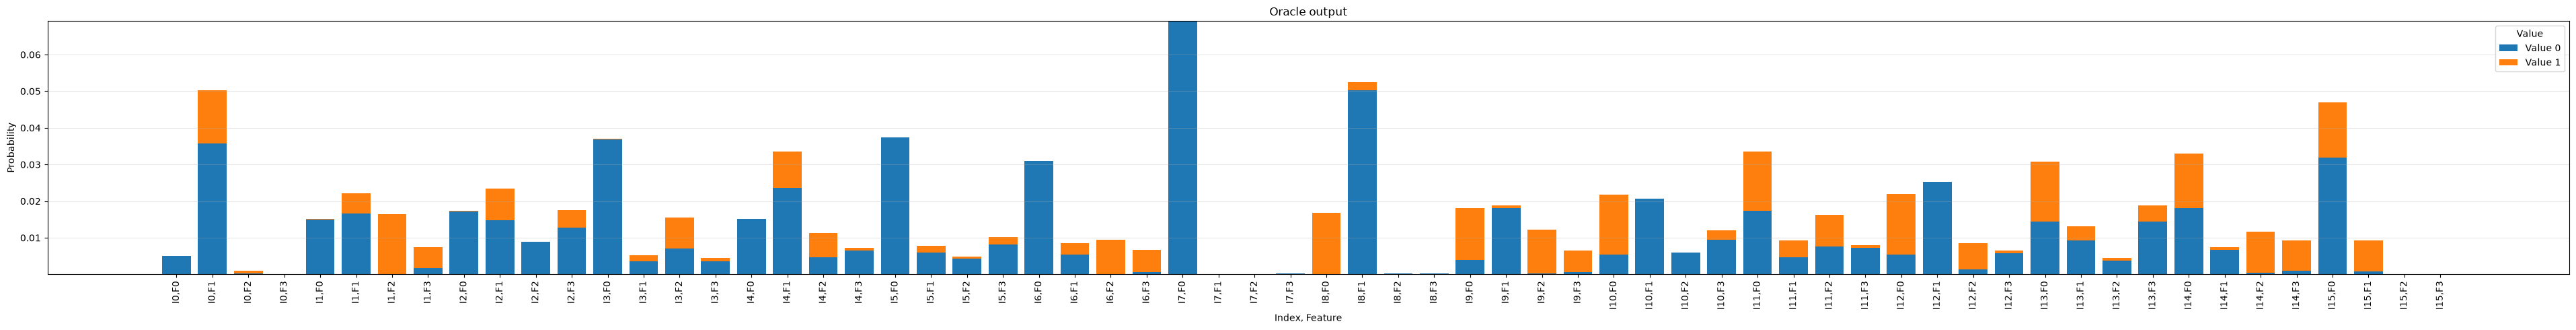


Oracle output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.071                   -0.008                   
0                        1                        -0.189                   -0.121                   
0                        2                        -0.016                   +0.026                   
0                        3                        -0.000                   -0.001                   
1                        0                        -0.122                   +0.012                   
1                        1                        -0.129                   -0.075                   
1                        2                        -0.010                   +0.128                   
1                        3                        +0.042                   +

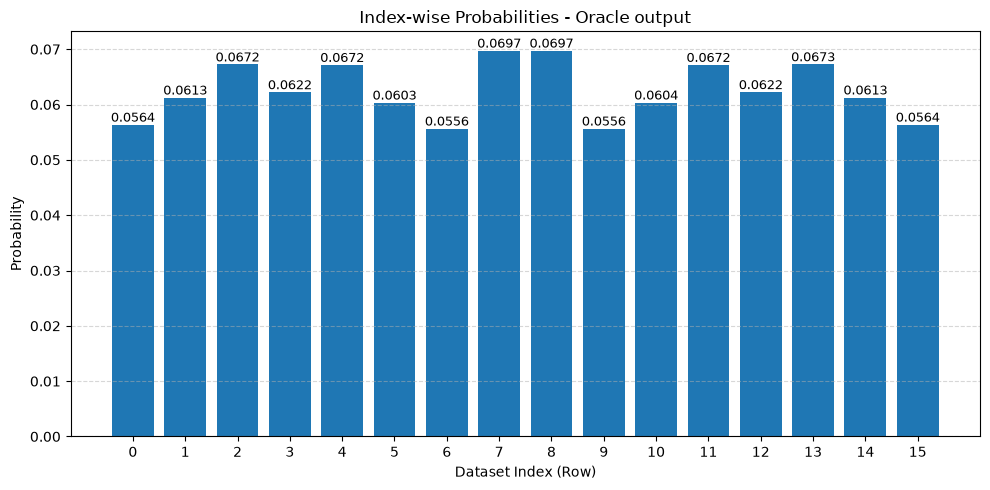



> Diffuser: 
Applying inverse of U...

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.12114623976971281-7.176469168655079e-17j)
|0000001> : (-0.0022833867384664083+1.7280692502359236e-17j)
|0000010> : (-0.05538953998745742+1.769769767750687e-17j)
|0000011> : (-0.03535877122754202+5.154552994637174e-17j)
|0000100> : (-0.004650210016529722+1.8450048289765513e-17j)
|0000101> : (0.007570442342934626-1.1828128994327308e-17j)
|0000110> : (-0.00014530585396403981+2.516796581920641e-17j)
|0000111> : (-0.00019031258366296032-2.4075188036863288e-17j)
|0001000> : (-0.20871718298223746-6.210166026520288e-17j)
|0001001> : (0.0035216225117434452+2.801139391995182e-17j)
|0001010> : (-0.03780894735776635+2.892710750877266e-17j)
|0001011> : (-0.021840013442489647+7.598326421929023e-17j)
|0001100> : (-0.002806594185118339+4.472085860462049e-17j)
|0001101> : (0.03753992873700077+2.2626492742819638e-18j)
|0001110> : (0.012354894891846215-8.211642377129261e-18j)
|0001111> : (0.021991269558445665-1.5815299639795534e-17j)
|0010000> : (-0.223457768

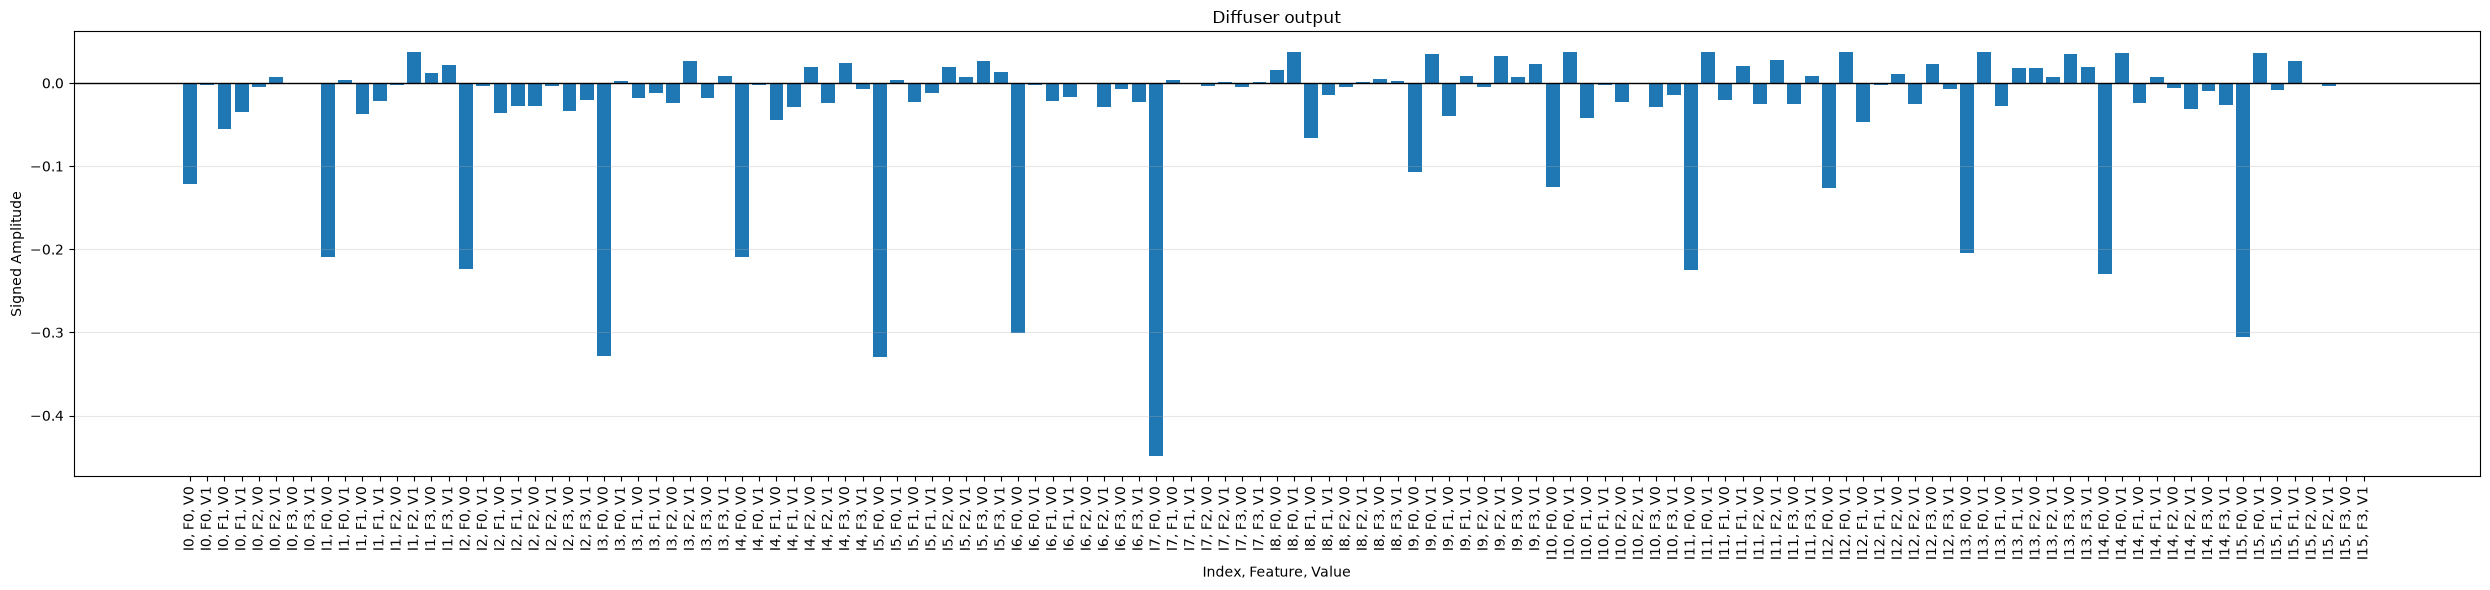


Sum of probabilities: 1.0000000000
Check passed: Sum of probabilities equals 1.


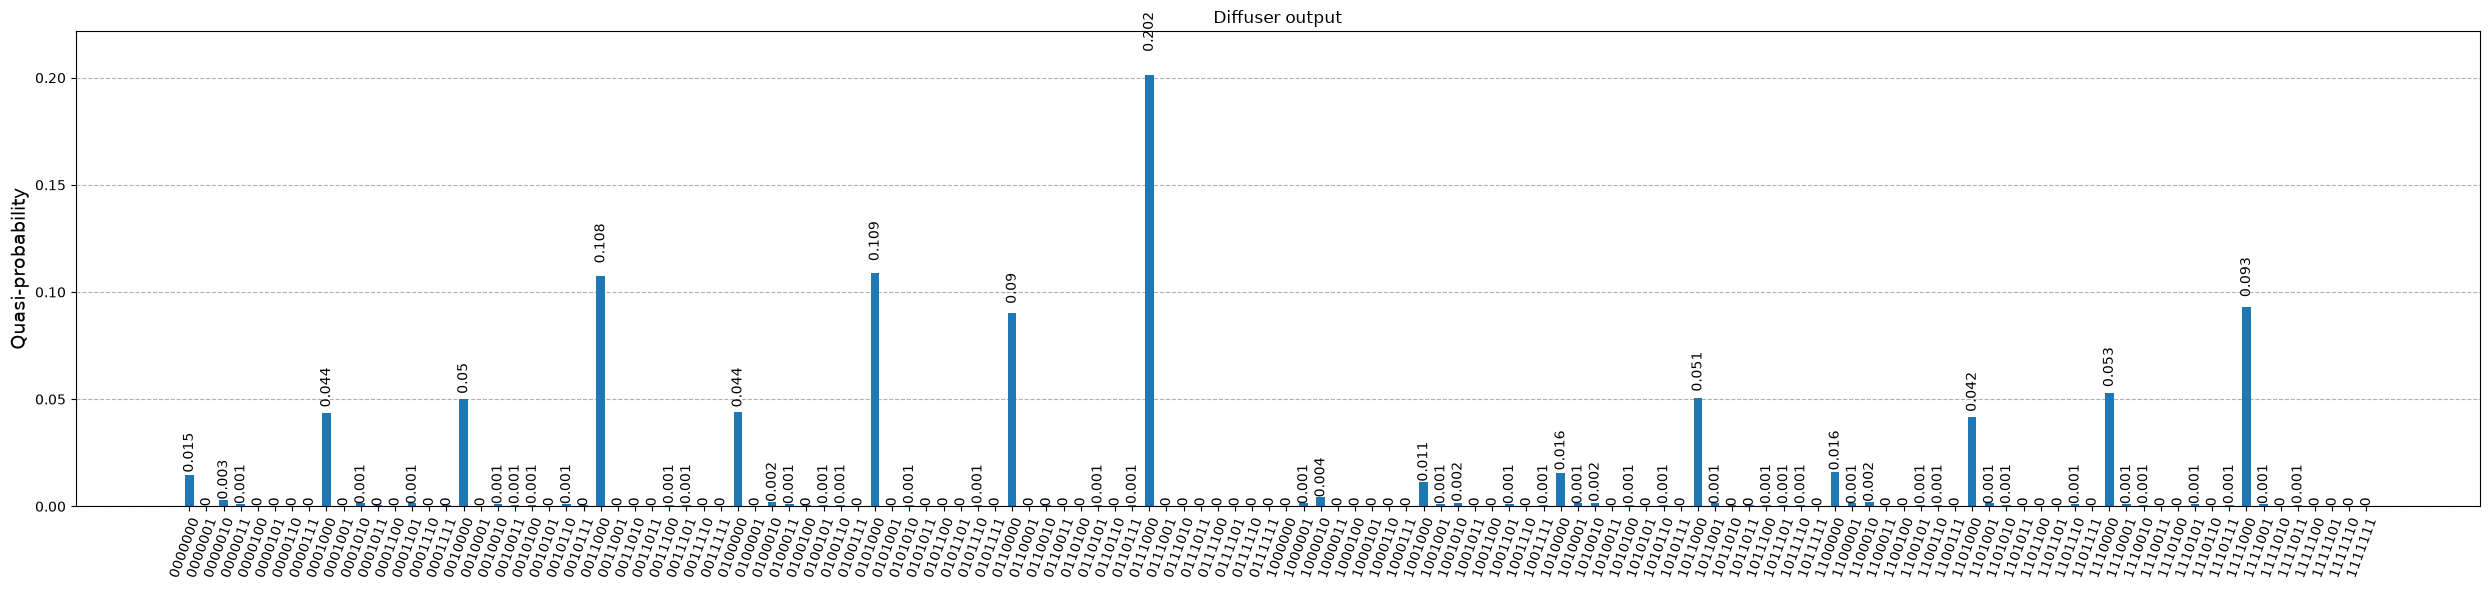

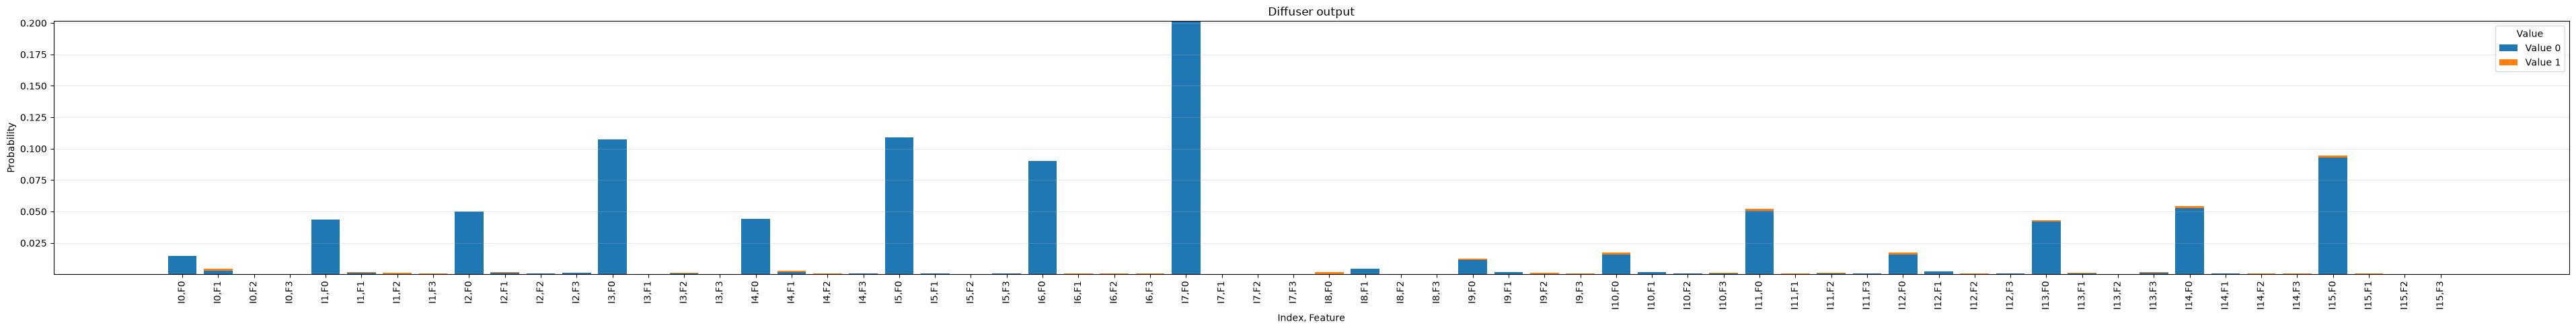


Diffuser output
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.121                   -0.002                   
0                        1                        -0.055                   -0.035                   
0                        2                        -0.005                   +0.008                   
0                        3                        -0.000                   -0.000                   
1                        0                        -0.209                   +0.004                   
1                        1                        -0.038                   -0.022                   
1                        2                        -0.003                   +0.038                   
1                        3                        +0.012                  

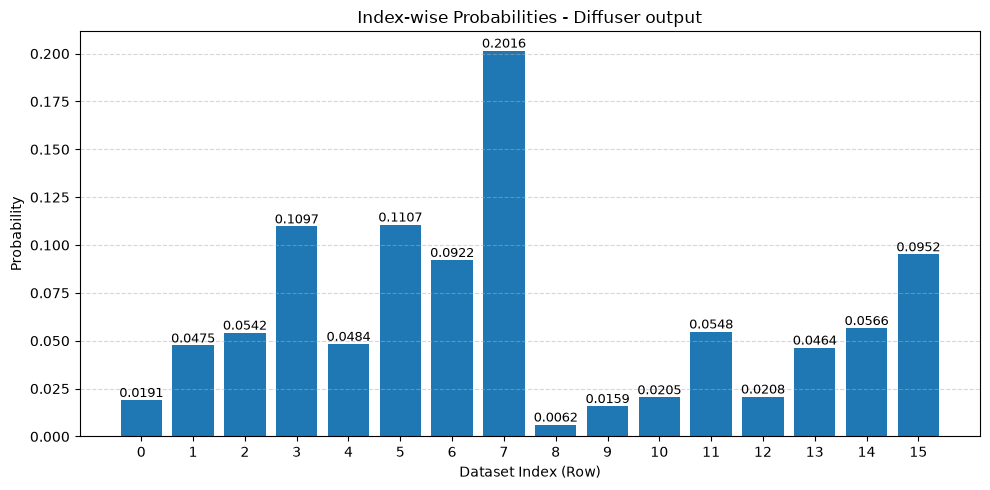


FINAL MEASUREMENT

Index measurement results for (2000) shots:
{'1001': 32, '0110': 204, '1100': 44, '0100': 104, '0011': 198, '0001': 104, '1011': 121, '1010': 38, '1000': 14, '1110': 105, '0101': 203, '0111': 399, '1101': 95, '1111': 202, '0000': 35, '0010': 102}


In [29]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters_neqr_fidelity,
    depth_A=pqc_depth_for_dataset_encoder, depth_B=pqc_depth_for_query_encoder,
    num_of_iter=1, scheme="NEQR"
)

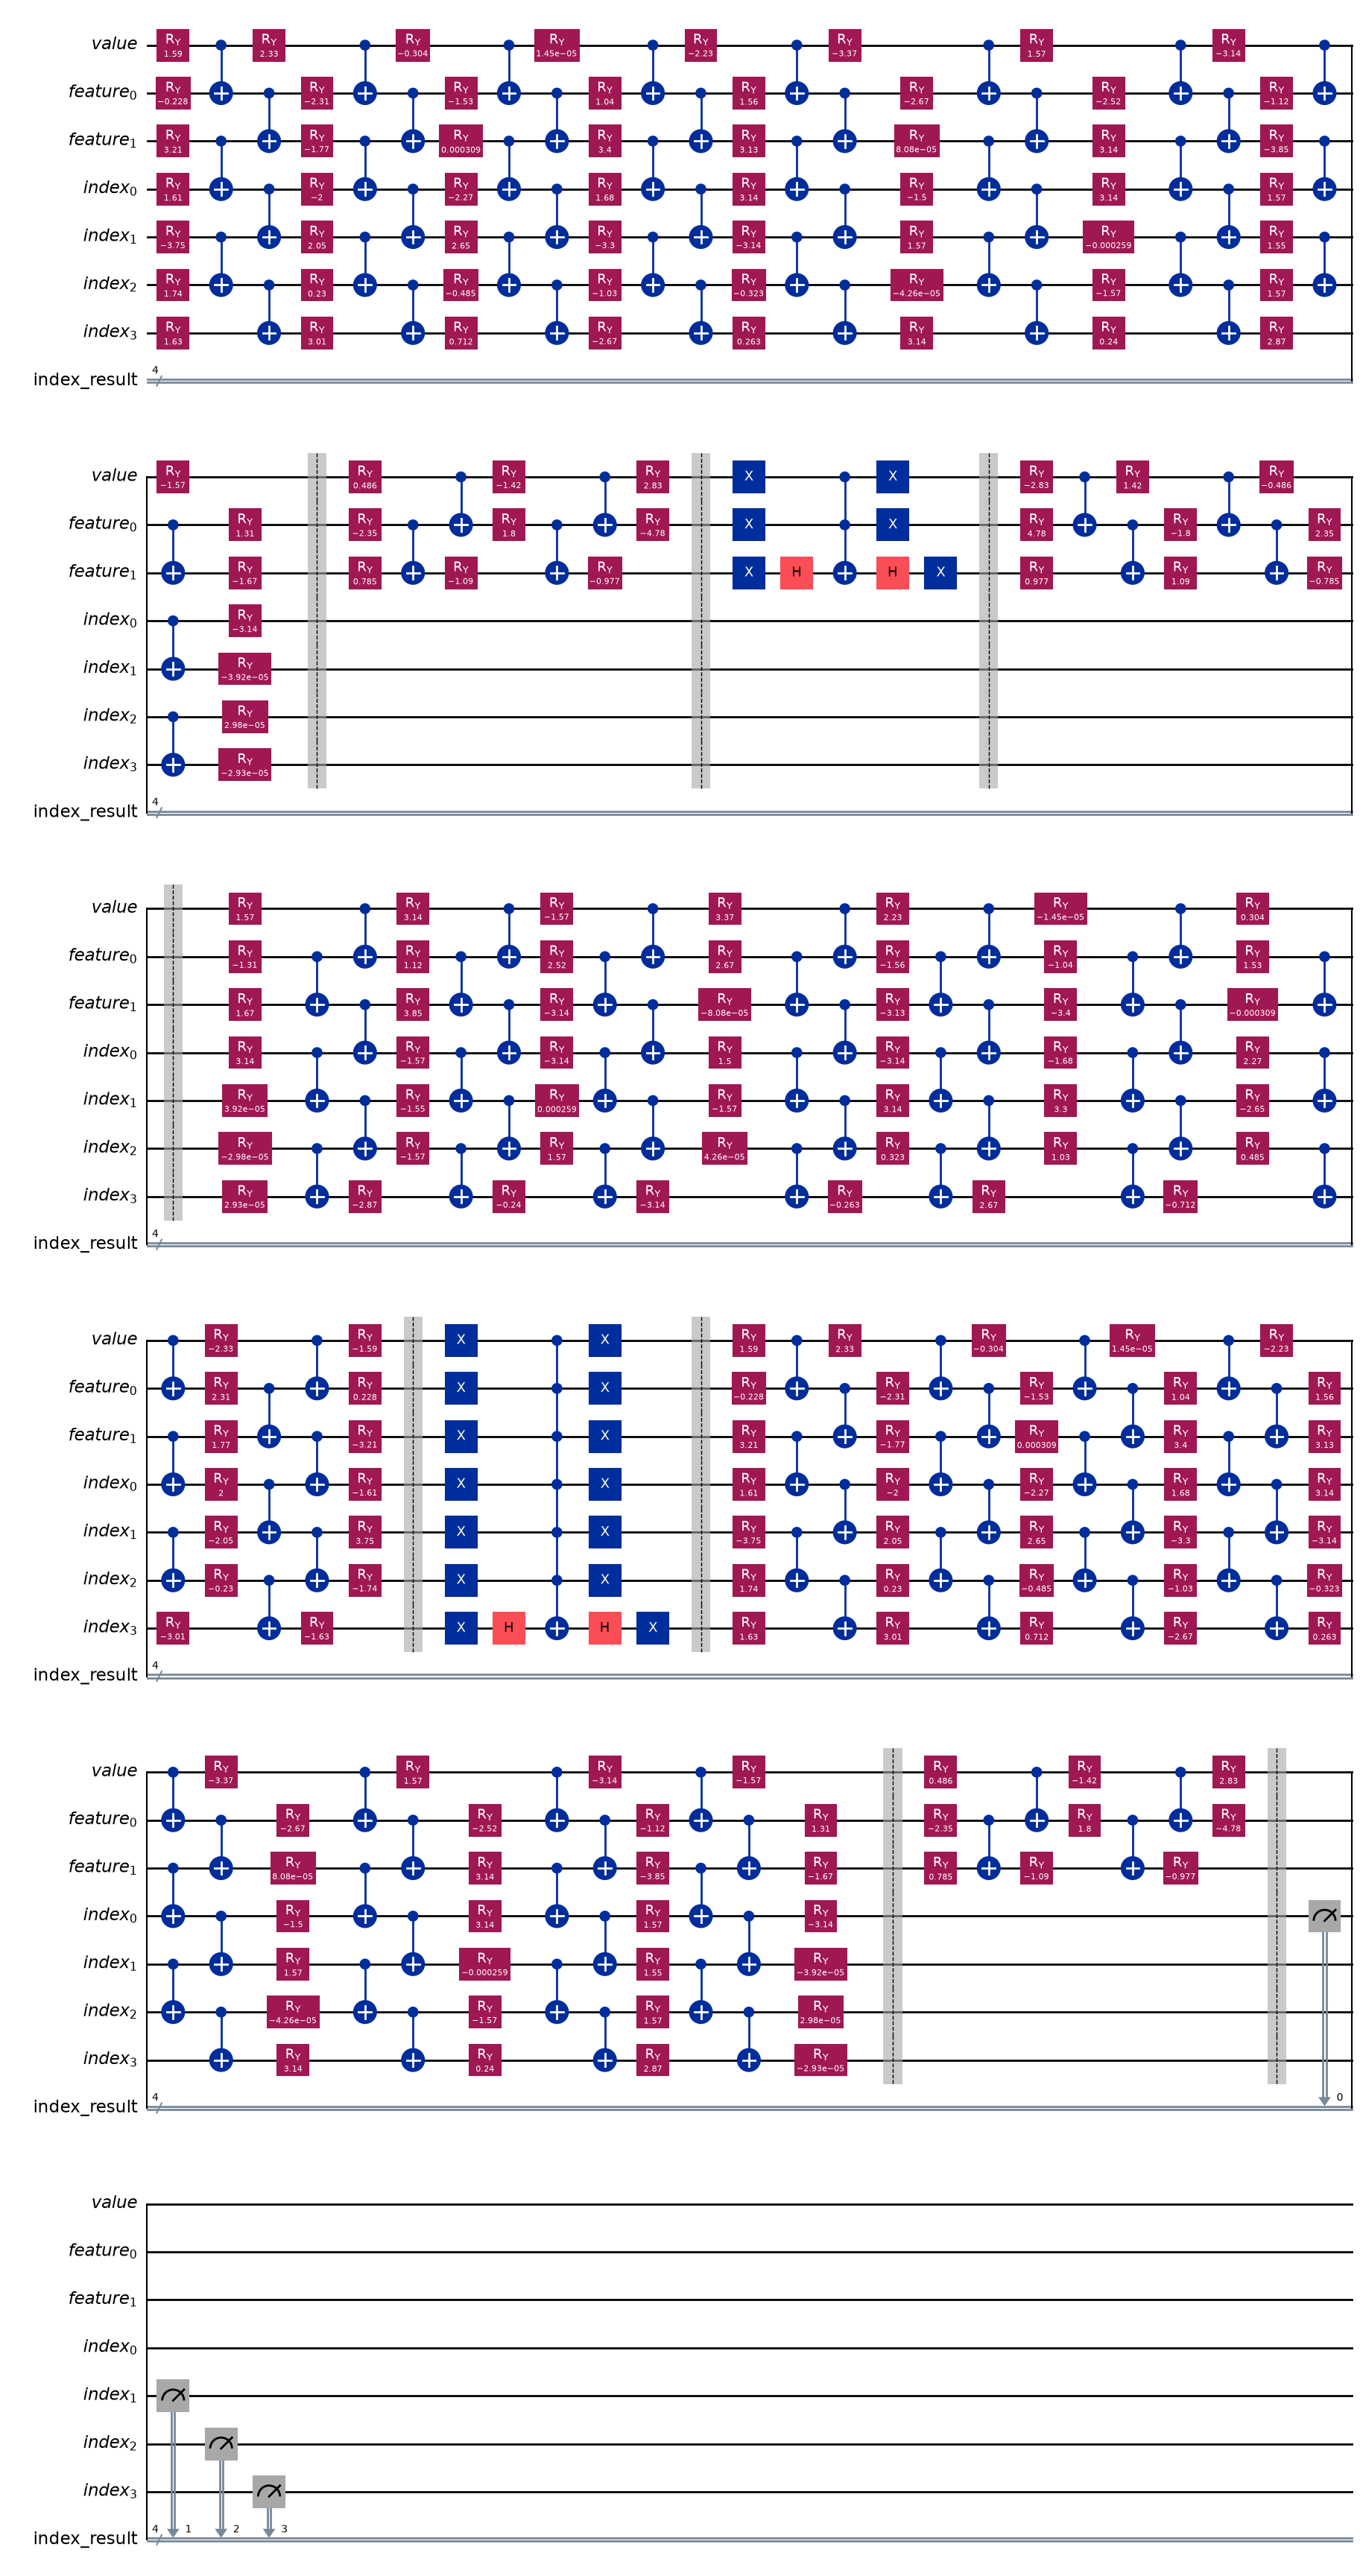

In [26]:
GS.draw_circuit()

In [27]:
GS.analysis()

REGISTER ANALYSIS
Dataset size (N): 16
Index qubits: 4
Data qubits: 2
Total qubits: 7
Classical bits: 4

CIRCUIT ANALYSIS
Circuit width: 11
Circuit size: 402
Circuit depth/layers: 107

OPERATION COUNT
OrderedDict({'ry': 216, 'cx': 156, 'x': 20, 'barrier': 8, 'h': 4, 'measure': 4, 'ccx': 1, 'mcx': 1})
